# Escolaridade e Empregabilidade Juvenil no Brasil
### Global Solution — Modelagem Linear para Aprendizado de Máquina · Desafio CitizenTech

**Integrantes:**
- `João Pedro Sousa` — RM `573962`
- `Matheus Evangelista Silva` — RM `568593`
- `Murilo Lima de Carvalho` — RM `570156`

---

**Pergunta de pesquisa.** Existe associação entre o nível de escolaridade e a inserção dos jovens brasileiros de 18 a 24 anos no mercado de trabalho, e como a escolaridade se relaciona com seus rendimentos?

**Hipóteses.**
- **H1-A:** maior escolaridade está associada a maior probabilidade de ocupação (entre jovens na força de trabalho).
- **H1-B:** maior escolaridade está associada a maior rendimento habitual (entre jovens ocupados).

> O projeto investiga **associações e capacidade preditiva**. Nenhuma conclusão deste notebook deve ser lida como causalidade.

**Base de dados.** PNAD Contínua / IBGE, 4º trimestre de 2024, jovens de 18 a 24 anos (dados reais, microdados oficiais). Fonte primaria: <https://www.ibge.gov.br/estatisticas/sociais/trabalho/9173-pesquisa-nacional-por-amostra-de-domicilios-continua-trimestral.html>

<https://www.ibge.gov.br/estatisticas/downloads-estatisticas.html?caminho=Trabalho_e_Rendimento/Pesquisa_Nacional_por_Amostra_de_Domicilios_continua/Trimestral/Microdados/2024>

Base de dados filtrada(18-24 anos): <https://github.com/JP-Sousa/GS-MLAM-Citizen-Tech/blob/main/data/source/pnad_jovens_18_24_2024q4.csv>

---

### Roteiro do notebook

| Etapa | Conteúdo |
|---|---|
| 1 | Inspeção inicial dos dados |
| 2 | Tratamento e construção das bases A, B e C |
| 3 | Análise exploratória |
| 4 | Distribuição Normal |
| 5 | Testes de hipóteses para a média |
| 6 | Análise bivariada e regressão linear simples |
| 7 | Regressão linear múltipla |
| 8 | Regressão logística binária |
| 9 | Síntese, hipóteses, limitações e checklist |

## Configuração do ambiente

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
import os, warnings
from IPython.display import display, Markdown
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore")

# ---------- parâmetros globais ----------
SEED = 42
np.random.seed(SEED)
SALARIO_MINIMO_2024 = 1412.0   # valor nacional vigente em 2024 (referência para leitura dos rendimentos)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

DIR_FIG, DIR_TAB, DIR_PROC = "results/figures", "results/tables", "data/processed"
for d in (DIR_FIG, DIR_TAB, DIR_PROC):
    os.makedirs(d, exist_ok=True)

RES = {}          # dicionário com os resultados numéricos de cada etapa (usado na síntese final)
RELATORIO = []    # relatorios de cada etapa

# ---------- formatação em português ----------
def num(x, d=2):
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def brl(x, d=2):
    return "R$ " + num(x, d)

def inteiro(n):
    return f"{int(n):,}".replace(",", ".")

def pct(x, d=1):
    """x em proporção (0-1)."""
    return num(x * 100, d) + "%"

def pnum(p):
    """p-valor só com o número (para tabelas)."""
    return "< 0,0001" if p < 1e-4 else num(p, 4)

def pval(p):
    """p-valor já com o operador, para frases: 'p {pval(p)}' → 'p < 0,0001' ou 'p = 0,0123'."""
    return "< 0,0001" if p < 1e-4 else "= " + num(p, 4)

# ---------- funções interpretativas ----------
def forca_corr(r):
    a = abs(r)
    if a < 0.10: return "praticamente nula"
    if a < 0.30: return "fraca"
    if a < 0.50: return "moderada"
    if a < 0.70: return "forte"
    return "muito forte"

def sentido(x):
    return "positiva" if x > 0 else ("negativa" if x < 0 else "nula")

def classificar_prob(p, tol=1e-4):
    """Convenção adotada: 0 = impossível; (0, 0,5) = improvável; 0,5 = equiprovável; (0,5, 1) = provável; 1 = certo."""
    if p <= 1e-9:          return "Evento impossível"
    if p >= 1 - 1e-9:      return "Evento certo"
    if abs(p - 0.5) <= tol: return "Evento equiprovável (≈ 50%)"
    return "Evento improvável (< 50%)" if p < 0.5 else "Evento provável (> 50%)"

def equacao(params, y="Y", d_int=2, d_coef=4):
    txt = f"{y} = {num(params['Intercept'], d_int)}"
    for k, v in params.items():
        if k == "Intercept": continue
        txt += f" {'+' if v >= 0 else '−'} {num(abs(v), d_coef)}·{k}"
    return txt

def p_unilateral(p_bilateral, coef, direcao=">"):
    """Converte o p-valor bilateral do coeficiente em p-valor unilateral (H1: beta > 0 ou beta < 0)."""
    if direcao == ">":
        return p_bilateral / 2 if coef > 0 else 1 - p_bilateral / 2
    return p_bilateral / 2 if coef < 0 else 1 - p_bilateral / 2

def salvar_fig(nome):
    plt.tight_layout()
    plt.savefig(f"{DIR_FIG}/{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

def salvar_tab(df_tab, nome, index=True):
    df_tab.to_csv(f"{DIR_TAB}/{nome}.csv", index=index, encoding="utf-8-sig")

def relatar(titulo, linhas):
    """Exibe e registra os achados de uma etapa (texto gerado a partir dos resultados calculados)."""
    texto = f"### {titulo}\n\n" + "\n".join(f"- {l}" for l in linhas)
    RELATORIO.append(texto)
    display(Markdown(texto))

print("Ambiente configurado. SEED =", SEED)

Ambiente configurado. SEED = 42


In [3]:
url = 'https://raw.githubusercontent.com/JP-Sousa/GS-MLAM-Citizen-Tech/refs/heads/main/data/source/pnad_jovens_18_24_2024q4.csv'
df_jovens = pd.read_csv(url)

print("Dataset carregado com sucesso!")
display(df_jovens.head())

Dataset carregado com sucesso!


,Ano,Trimestre,UF,V1022,V1028,V2001,V2007,V2009,V4039,VD3005,VD4001,VD4002,VD4016,VD4031
0,2024,4,11,1,235.636327,2,2,22,NaN,12.0,2.0,NaN,NaN,NaN
1,2024,4,11,1,235.636327,2,1,22,44.0,12.0,1.0,1.0,1412.0,44.0
2,2024,4,11,1,180.886550,4,2,21,NaN,14.0,2.0,NaN,NaN,NaN
3,2024,4,11,1,187.315151,5,2,23,44.0,12.0,1.0,1.0,1500.0,44.0
4,2024,4,11,1,210.329403,3,2,19,NaN,8.0,2.0,NaN,NaN,NaN


---
# Etapa 1 — Inspeção inicial dos dados

Antes de qualquer tratamento, é preciso entender o que a base contém: tamanho, tipos, domínio de cada variável, ausências e possíveis inconsistências.

**Objetivos**
1. **Inspecionar antes de limpar.** Toda regra de tratamento da Etapa 2 precisa estar apoiada em um problema que foi de fato medido aqui, e não em suposição.
2. **Distinguir ausência *estrutural* de ausência por erro.** Na PNAD, rendimento (`VD4016`) e horas trabalhadas (`V4039`, `VD4031`) só existem para pessoas **ocupadas**; para quem está desocupado ou fora da força de trabalho o valor ausente é esperado e **não deve ser imputado**. Imputar criaria rendimento fictício para quem não trabalha.
3. **Checar a coerência entre as variáveis de condição de trabalho.** `VD4001` (força de trabalho) e `VD4002` (ocupação) precisam ser compatíveis: `VD4002` só deveria estar preenchida para quem está na força de trabalho.
4. **Linhas repetidas não serão removidas automaticamente.** A base não tem identificador de pessoa. Irmãos do mesmo domicílio podem ter idade, sexo e escolaridade iguais e compartilham o mesmo peso amostral, o que gera linhas idênticas legítimas. Remover seria perder observações reais.
5. **Dicionário de variáveis.** Os códigos e categorias abaixo seguem o dicionário oficial da PNAD Contínua e devem ser conferidos contra o dicionário do 4º trimestre de 2024 antes da entrega (recomendação da própria proposta do projeto).

In [4]:
print("Dimensões (linhas, colunas):", df_jovens.shape)
print("Períodos presentes (Ano, Trimestre):", df_jovens[["Ano", "Trimestre"]].drop_duplicates().values.tolist())
print()
df_jovens.info()

Dimensões (linhas, colunas): (44020, 14)
Períodos presentes (Ano, Trimestre): [[2024, 4]]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44020 entries, 0 to 44019
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Ano        44020 non-null  int64  
 1   Trimestre  44020 non-null  int64  
 2   UF         44020 non-null  int64  
 3   V1022      44020 non-null  int64  
 4   V1028      44020 non-null  float64
 5   V2001      44020 non-null  int64  
 6   V2007      44020 non-null  int64  
 7   V2009      44020 non-null  int64  
 8   V4039      24682 non-null  float64
 9   VD3005     44020 non-null  float64
 10  VD4001     44020 non-null  float64
 11  VD4002     28479 non-null  float64
 12  VD4016     23716 non-null  float64
 13  VD4031     24682 non-null  float64
dtypes: float64(7), int64(7)
memory usage: 4.7 MB


In [5]:
dicionario = pd.DataFrame([
    ("Ano / Trimestre", "Período de referência da entrevista", "Identificação"),
    ("UF", "Unidade da Federação (código IBGE de 2 dígitos; o 1º dígito indica a região)", "Categórica"),
    ("V1022", "Situação do domicílio: 1 = urbana, 2 = rural", "Categórica"),
    ("V1028", "Peso amostral (fator de expansão da pessoa)", "Quantitativa"),
    ("V2001", "Número de pessoas no domicílio", "Quantitativa"),
    ("V2007", "Sexo: 1 = homem, 2 = mulher", "Categórica"),
    ("V2009", "Idade (anos completos)", "Quantitativa"),
    ("V4039", "Horas habitualmente trabalhadas por semana no trabalho principal (só ocupados)", "Quantitativa"),
    ("VD3005", "Anos de estudo (0 a 16; 16 = 16 anos ou mais)", "Quantitativa / ordinal"),
    ("VD4001", "Condição na força de trabalho: 1 = na força de trabalho, 2 = fora da força de trabalho", "Categórica"),
    ("VD4002", "Condição de ocupação: 1 = ocupada, 2 = desocupada (vazio para quem está fora da força)", "Categórica"),
    ("VD4016", "Rendimento mensal habitual do trabalho principal, em R$ (só ocupados)", "Quantitativa"),
    ("VD4031", "Horas habitualmente trabalhadas por semana em todos os trabalhos (só ocupados)", "Quantitativa"),
], columns=["Variável", "Descrição", "Tipo"])
display(dicionario)
salvar_tab(dicionario, "dicionario_variaveis", index=False)

,Variável,Descrição,Tipo
0,Ano / Trimestre,Período de referência da entrevista,Identificação
1,UF,Unidade da Federação (código IBGE de 2 dígitos...,Categórica
2,V1022,"Situação do domicílio: 1 = urbana, 2 = rural",Categórica
3,V1028,Peso amostral (fator de expansão da pessoa),Quantitativa
4,V2001,Número de pessoas no domicílio,Quantitativa
5,V2007,"Sexo: 1 = homem, 2 = mulher",Categórica
6,V2009,Idade (anos completos),Quantitativa
7,V4039,Horas habitualmente trabalhadas por semana no ...,Quantitativa
8,VD3005,Anos de estudo (0 a 16; 16 = 16 anos ou mais),Quantitativa / ordinal
9,VD4001,Condição na força de trabalho: 1 = na força de...,Categórica


In [6]:
ausentes = pd.DataFrame({
    "tipo": df_jovens.dtypes.astype(str),
    "n_ausentes": df_jovens.isna().sum(),
    "pct_ausentes": (df_jovens.isna().mean() * 100).round(2),
    "n_valores_distintos": df_jovens.nunique(),
})
display(ausentes)

print("\nDomínio das variáveis categóricas (contagem por valor, incluindo ausentes):")
for col in ["V1022", "V2007", "VD4001", "VD4002"]:
    print(f"\n{col}")
    display(df_jovens[col].value_counts(dropna=False).sort_index().to_frame("n").T)

print("\nUF (27 códigos esperados):", df_jovens["UF"].nunique(), "distintos")
print("\nEstatísticas descritivas das variáveis quantitativas:")
display(df_jovens[["V2009", "V2001", "VD3005", "V4039", "VD4031", "VD4016", "V1028"]]
        .describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2))

,tipo,n_ausentes,pct_ausentes,n_valores_distintos
Ano,int64,0,0.00,1
Trimestre,int64,0,0.00,1
UF,int64,0,0.00,27
V1022,int64,0,0.00,2
V1028,float64,0,0.00,36119
V2001,int64,0,0.00,17
V2007,int64,0,0.00,2
V2009,int64,0,0.00,7
V4039,float64,19338,43.93,87
VD3005,float64,0,0.00,17



Domínio das variáveis categóricas (contagem por valor, incluindo ausentes):

V1022


V1022,1,2
n,33122,10898



V2007


V2007,1,2
n,22286,21734



VD4001


VD4001,1.0,2.0
n,28479,15541



VD4002


VD4002,1.0,2.0,NaN
n,24682,3797,15541



UF (27 códigos esperados): 27 distintos

Estatísticas descritivas das variáveis quantitativas:


,count,mean,std,min,1%,25%,50%,75%,99%,max
V2009,44020.0,20.97,2.03,18.00,18.00,19.00,21.00,23.00,24.00,24.00
V2001,44020.0,3.72,1.55,1.00,1.00,3.00,4.00,4.00,9.00,19.00
VD3005,44020.0,11.46,2.59,0.00,0.00,11.00,12.00,12.00,16.00,16.00
V4039,24682.0,37.83,11.29,1.00,6.00,30.00,40.00,44.00,60.00,112.00
VD4031,24682.0,38.15,11.57,1.00,6.00,30.00,40.00,44.00,68.00,116.00
VD4016,23716.0,1703.65,1431.54,20.00,150.00,1200.00,1412.00,2000.00,6000.00,70000.00
V1028,44020.0,488.20,465.22,5.24,48.11,205.15,347.86,603.58,2221.41,10117.35


In [7]:
d = df_jovens
ocup = d["VD4002"] == 1
checagens = pd.DataFrame([
    ("Idade fora do intervalo 18–24", (~d["V2009"].between(18, 24)).sum()),
    ("Período diferente de 2024/T4", ((d["Ano"] != 2024) | (d["Trimestre"] != 4)).sum()),
    ("Anos de estudo ausentes ou fora de 0–16", (~d["VD3005"].between(0, 16)).sum()),
    ("Peso amostral ausente ou ≤ 0", (d["V1028"].isna() | (d["V1028"] <= 0)).sum()),
    ("Ocupados sem rendimento (VD4016 ausente)", (ocup & d["VD4016"].isna()).sum()),
    ("Ocupados com rendimento ≤ 0", (ocup & (d["VD4016"] <= 0)).sum()),
    ("Ocupados sem horas habituais (V4039 ausente)", (ocup & d["V4039"].isna()).sum()),
    ("Ocupados com mais de 84 h/semana (implausível ou muito extremo)", (ocup & (d["V4039"] > 84)).sum()),
    ("VD4002 preenchida, mas fora da força de trabalho (VD4001 = 2)", (d["VD4002"].notna() & (d["VD4001"] == 2)).sum()),
    ("Na força de trabalho (VD4001 = 1), mas VD4002 ausente", ((d["VD4001"] == 1) & d["VD4002"].isna()).sum()),
    ("Rendimento informado para quem não é ocupado", (d["VD4016"].notna() & ~ocup).sum()),
    ("Linhas totalmente duplicadas (mantidas; ver decisão 4)", d.duplicated().sum()),
], columns=["Verificação", "n_registros"])
checagens["% da base"] = (checagens["n_registros"] / len(d) * 100).round(3)
display(checagens)
salvar_tab(checagens, "etapa1_checagens_consistencia", index=False)
RES["etapa1_checagens"] = checagens

,Verificação,n_registros,% da base
0,Idade fora do intervalo 18–24,0,0.000
1,Período diferente de 2024/T4,0,0.000
2,Anos de estudo ausentes ou fora de 0–16,0,0.000
3,Peso amostral ausente ou ≤ 0,0,0.000
4,Ocupados sem rendimento (VD4016 ausente),966,2.194
5,Ocupados com rendimento ≤ 0,0,0.000
6,Ocupados sem horas habituais (V4039 ausente),0,0.000
7,Ocupados com mais de 84 h/semana (implausível ...,18,0.041
8,"VD4002 preenchida, mas fora da força de trabal...",0,0.000
9,"Na força de trabalho (VD4001 = 1), mas VD4002 ...",0,0.000


In [8]:
n, n_col = df_jovens.shape
n_ocup = int((df_jovens["VD4002"] == 1).sum())
n_desoc = int((df_jovens["VD4002"] == 2).sum())
n_fora = int((df_jovens["VD4001"] == 2).sum())
problemas = checagens[~checagens["Verificação"].str.contains("duplicadas")]
com_problema = problemas[problemas["n_registros"] > 0]

dup = int(checagens.loc[checagens["Verificação"].str.contains("duplicadas"), "n_registros"].iloc[0])
linhas = [
    f"A base tem **{inteiro(n)}** registros e **{n_col}** colunas, todas do **{int(df_jovens['Trimestre'].iloc[0])}º trimestre de {int(df_jovens['Ano'].iloc[0])}**.",
    f"Composição por condição de trabalho: **{inteiro(n_ocup)}** ocupados ({pct(n_ocup/n)}), **{inteiro(n_desoc)}** desocupados ({pct(n_desoc/n)}) e **{inteiro(n_fora)}** fora da força de trabalho ({pct(n_fora/n)}).",
    "As colunas `V4039`, `VD4016` e `VD4031` têm valores ausentes **estruturais**: só existem para ocupados. Isso explica a maior parte das ausências na tabela e **não** indica erro de coleta.",
]
if len(com_problema) == 0:
    linhas.append("Nenhuma das checagens de consistência identificou registros problemáticos.")
else:
    for _, r in com_problema.iterrows():
        linhas.append(f"Checagem sinalizada: *{r['Verificação']}* → **{inteiro(r['n_registros'])}** registros ({num(r['% da base'], 2)}% da base).")
linhas.append("Não há linhas totalmente idênticas na base." if dup == 0 else f"Há {inteiro(dup)} linhas idênticas; elas serão **mantidas** pelo motivo explicado na decisão 4.")
relatar("Relatório da inspecção", linhas)

### Relatório da inspecção

- A base tem **44.020** registros e **14** colunas, todas do **4º trimestre de 2024**.
- Composição por condição de trabalho: **24.682** ocupados (56,1%), **3.797** desocupados (8,6%) e **15.541** fora da força de trabalho (35,3%).
- As colunas `V4039`, `VD4016` e `VD4031` têm valores ausentes **estruturais**: só existem para ocupados. Isso explica a maior parte das ausências na tabela e **não** indica erro de coleta.
- Checagem sinalizada: *Ocupados sem rendimento (VD4016 ausente)* → **966** registros (2,19% da base).
- Checagem sinalizada: *Ocupados com mais de 84 h/semana (implausível ou muito extremo)* → **18** registros (0,04% da base).
- Há 108 linhas idênticas; elas serão **mantidas** pelo motivo explicado na decisão 4.

---
# Etapa 2 — Tratamento dos dados e construção das bases de análise

Decisões de tratamento:

1. **Renomear variáveis** para nomes legíveis (`V2009` → `idade`, `VD3005` → `anos_estudo` etc.). Reduz erro de leitura nas fórmulas dos modelos e facilita a interpretação no relatório.
2. **Três bases, três populações.** Misturar populações distorce as conclusões:
   - **Base A — todos os jovens de 18 a 24 anos válidos:** perfil e análise descritiva.
   - **Base B — jovens ocupados com rendimento e horas válidos:** distribuição normal, testes de média, regressões lineares. Só faz sentido falar de rendimento do trabalho para quem trabalha.
   - **Base C — jovens na força de trabalho (ocupados + desocupados):** regressão logística.
3. **Pessoas fora da força de trabalho não são tratadas como desempregadas.** Desocupado é quem procura trabalho e não encontra; quem estuda sem procurar emprego, por exemplo, está fora da força. Por isso a Base C exclui esse grupo. A consequência (um possível viés de seleção, já que muitos estudantes ficam de fora) será discutida nas limitações.
4. **Rendimento válido = maior que zero.** Rendimento zero ou ausente entre ocupados corresponde a trabalho não remunerado ou sem informação; incluí-lo como "R$ 0" distorceria média e regressão. O número de registros excluídos por esse critério é reportado.
5. **Horas válidas = entre 1 e 168 por semana.** 168 é o total de horas de uma semana; acima disso o valor seria fisicamente impossível. Jornadas muito longas, mas possíveis (por exemplo, acima de 70 h), são **mantidas** e apenas sinalizadas, porque podem ser reais.
6. **Valores extremos de rendimento não são removidos na base principal.** Rendimentos altos de jovens são raros, mas são dados reais. Em vez de excluí-los, o notebook mede o efeito deles nos modelos por meio de **análises de robustez**: modelo com rendimento em logaritmo, modelo sem o 1% mais alto e modelo ponderado pelo peso amostral.
7. **Faixas de escolaridade** (`0–8`, `9–11`, `12`, `13–15`, `16` anos) são criadas apenas para tabelas e gráficos. Os modelos usam `anos_estudo` como variável numérica, como definido na proposta.
8. **Peso amostral (`V1028`) é preservado** em todas as bases. As estatísticas descritivas são mostradas com e sem ponderação; os modelos principais são sem ponderação (como trabalhado em aula) e há versões ponderadas como robustez.
9. **Nenhuma imputação.** Registros com ausência em variável essencial ao modelo são excluídos, e a contagem é registrada no funil de seleção.

In [9]:
df = df_jovens.copy()

# 1) nomes legíveis
df = df.rename(columns={
    "UF": "uf", "V1022": "situacao_cod", "V1028": "peso", "V2001": "tamanho_domicilio",
    "V2007": "sexo_cod", "V2009": "idade", "V4039": "horas_semanais", "VD3005": "anos_estudo",
    "VD4001": "forca_trabalho_cod", "VD4002": "ocupacao_cod", "VD4016": "rendimento",
    "VD4031": "horas_todos_trabalhos",
})

# 2) rótulos e variáveis derivadas
df["sexo"] = df["sexo_cod"].map({1: "Homem", 2: "Mulher"})
df["situacao"] = df["situacao_cod"].map({1: "Urbana", 2: "Rural"})
df["regiao"] = (df["uf"] // 10).map({1: "Norte", 2: "Nordeste", 3: "Sudeste", 4: "Sul", 5: "Centro-Oeste"})
df["sexo_binario"] = (df["sexo_cod"] == 2).astype(int)        # 1 = mulher
df["urbano_binario"] = (df["situacao_cod"] == 1).astype(int)  # 1 = urbano

df["status_ocupacao"] = np.select(
    [df["forca_trabalho_cod"] == 2, df["ocupacao_cod"] == 1, df["ocupacao_cod"] == 2],
    ["Fora da força de trabalho", "Ocupado", "Desocupado"], default="Indefinido")
df["ocupado_binario"] = np.where(df["status_ocupacao"] == "Ocupado", 1.0,
                         np.where(df["status_ocupacao"] == "Desocupado", 0.0, np.nan))

faixas = ["0–8 anos", "9–11 anos", "12 anos", "13–15 anos", "16 anos"]
df["faixa_escolaridade"] = pd.cut(df["anos_estudo"], bins=[-1, 8, 11, 12, 15, 16], labels=faixas)
df["faixa_escolaridade"] = pd.Categorical(df["faixa_escolaridade"], categories=faixas, ordered=True)

# 3) Base A: jovens válidos
n_bruto = len(df)
essenciais = ["idade", "anos_estudo", "tamanho_domicilio", "peso", "uf", "sexo_cod", "situacao_cod"]
f_periodo = (df["Ano"] == 2024) & (df["Trimestre"] == 4)
f_idade = df["idade"].between(18, 24)
f_completo = df[essenciais].notna().all(axis=1) & df["anos_estudo"].between(0, 16) & (df["peso"] > 0)
f_status = df["status_ocupacao"] != "Indefinido"

base_A = df[f_periodo & f_idade & f_completo & f_status].copy()

# 4) Base B: ocupados com rendimento e horas válidos
ocupados = base_A[base_A["status_ocupacao"] == "Ocupado"]
mask_B = (ocupados["rendimento"].notna() & (ocupados["rendimento"] > 0)
          & ocupados["horas_semanais"].notna() & ocupados["horas_semanais"].between(1, 168))
base_B = ocupados[mask_B].copy()
base_B["log_rendimento"] = np.log(base_B["rendimento"])

# 5) Base C: força de trabalho (ocupados + desocupados)
base_C = base_A[base_A["status_ocupacao"].isin(["Ocupado", "Desocupado"])].copy()
base_C["ocupado_binario"] = base_C["ocupado_binario"].astype(int)

# 6) funil de seleção
funil = pd.DataFrame([
    ("Registros na base bruta", n_bruto),
    ("Base A — jovens 18–24, período correto, variáveis essenciais válidas, status definido", len(base_A)),
    ("   dos quais ocupados", len(ocupados)),
    ("   ocupados excluídos por rendimento ausente ou ≤ 0", int((~(ocupados["rendimento"].notna() & (ocupados["rendimento"] > 0))).sum())),
    ("   ocupados excluídos por horas ausentes ou fora de 1–168", int((~(ocupados["horas_semanais"].notna() & ocupados["horas_semanais"].between(1, 168))).sum())),
    ("Base B — ocupados com rendimento e horas válidos", len(base_B)),
    ("Base C — força de trabalho (ocupados + desocupados)", len(base_C)),
], columns=["Etapa de seleção", "n"])
display(funil)
salvar_tab(funil, "etapa2_funil_selecao", index=False)

# 7) exportação das bases tratadas (reprodutibilidade)
base_A.to_csv(f"{DIR_PROC}/base_A_jovens_18_24.csv", index=False, encoding="utf-8-sig")
base_B.to_csv(f"{DIR_PROC}/base_B_ocupados_rendimento.csv", index=False, encoding="utf-8-sig")
base_C.to_csv(f"{DIR_PROC}/base_C_forca_de_trabalho.csv", index=False, encoding="utf-8-sig")

assert base_B.groupby("regiao").size().min() >= 25, "Algum grupo regional tem menos de 25 observações na Base B"
RES["funil"] = funil

,Etapa de seleção,n
0,Registros na base bruta,44020
1,"Base A — jovens 18–24, período correto, variáv...",44020
2,dos quais ocupados,24682
3,ocupados excluídos por rendimento ausente o...,966
4,ocupados excluídos por horas ausentes ou fo...,0
5,Base B — ocupados com rendimento e horas válidos,23716
6,Base C — força de trabalho (ocupados + desocup...,28479


In [10]:
print("Tipos das variáveis da Base B:")
display(base_B[["rendimento", "log_rendimento", "anos_estudo", "idade", "horas_semanais", "tamanho_domicilio", "peso"]].dtypes.to_frame("dtype").T)
print("Observações por região na Base B (importante para os testes da Etapa 5):")
display(base_B["regiao"].value_counts().to_frame("n").T)

linhas_longas = int((base_B["horas_semanais"] > 70).sum())
p99 = base_B["rendimento"].quantile(0.99)
n_trim = int((base_B["rendimento"] > p99).sum())

linhas = [
    f"Partindo de **{inteiro(n_bruto)}** registros, a **Base A** ficou com **{inteiro(len(base_A))}** jovens ({inteiro(n_bruto - len(base_A))} excluídos por falhas de filtro ou validade).",
    f"A **Base B** (ocupados com rendimento e horas válidos) tem **{inteiro(len(base_B))}** observações; foram retirados **{inteiro(len(ocupados) - len(base_B))}** ocupados por rendimento ausente/≤ 0 ou horas inválidas.",
    f"A **Base C** (força de trabalho) tem **{inteiro(len(base_C))}** observações, das quais **{pct(base_C['ocupado_binario'].mean())}** ocupadas. Esse desbalanceamento de classes será tratado na Etapa 8.",
    f"Jornadas acima de 70 h/semana: **{inteiro(linhas_longas)}** casos ({pct(linhas_longas/len(base_B), 2)} da Base B). Foram **mantidos** (decisão 5), pois são possíveis.",
    f"O percentil 99 do rendimento é **{brl(p99)}**; **{inteiro(n_trim)}** observações estão acima dele. Elas permanecem na base principal e serão removidas apenas na **análise de robustez** (decisão 6).",
    "As três bases foram exportadas em `data/processed/` para que qualquer pessoa possa reproduzir as análises sem repetir o tratamento.",
]
relatar("Relatório do tratamento de dados", linhas)
RES.update(p99_rendimento=p99)

Tipos das variáveis da Base B:


,rendimento,log_rendimento,anos_estudo,idade,horas_semanais,tamanho_domicilio,peso
dtype,float64,float64,float64,int64,float64,int64,float64


Observações por região na Base B (importante para os testes da Etapa 5):


regiao,Nordeste,Sudeste,Sul,Norte,Centro-Oeste
n,6835,6250,4708,3170,2753


### Relatório do tratamento de dados

- Partindo de **44.020** registros, a **Base A** ficou com **44.020** jovens (0 excluídos por falhas de filtro ou validade).
- A **Base B** (ocupados com rendimento e horas válidos) tem **23.716** observações; foram retirados **966** ocupados por rendimento ausente/≤ 0 ou horas inválidas.
- A **Base C** (força de trabalho) tem **28.479** observações, das quais **86,7%** ocupadas. Esse desbalanceamento de classes será tratado na Etapa 8.
- Jornadas acima de 70 h/semana: **98** casos (0,41% da Base B). Foram **mantidos** (decisão 5), pois são possíveis.
- O percentil 99 do rendimento é **R$ 6.000,00**; **225** observações estão acima dele. Elas permanecem na base principal e serão removidas apenas na **análise de robustez** (decisão 6).
- As três bases foram exportadas em `data/processed/` para que qualquer pessoa possa reproduzir as análises sem repetir o tratamento.

---
# Etapa 3 — Análise exploratória

1. **Duas leituras para cada percentual: amostral e ponderada.** A amostra da PNAD não é uma amostra aleatória simples: cada pessoa representa um número diferente de brasileiros (`peso`). O percentual da amostra descreve a *amostra*; o ponderado aproxima a *população*. Mostrar os dois deixa visível se a ponderação muda a conclusão.
2. **Rendimento é descrito por mediana e percentis, além da média.** Rendimentos costumam ser assimétricos à direita; a média é puxada pelos valores altos e a mediana descreve melhor o jovem típico.
3. **Gráficos de rendimento com o eixo cortado no percentil 99.** Sem o corte, poucos valores extremos comprimiriam toda a distribuição. O corte afeta apenas a visualização; nenhum dado é removido.
4. **Taxa de ocupação medida apenas na força de trabalho** (Base C), e **não** sobre todos os jovens. Dividir ocupados pelo total de jovens misturaria desemprego com quem estuda ou não procura trabalho.
5. **Teste qui-quadrado entre faixa de escolaridade e ocupação**, com V de Cramér como tamanho de efeito. O p-valor sozinho cresce com o tamanho da amostra; o V diz se a associação é relevante na prática.
6. **Exibir também a distribuição de status por escolaridade na Base A**, para tornar visível quanto da diferença de escolaridade está associada a estar *fora* da força de trabalho (por exemplo, estudando).


Sexo — Base A


,n,% amostra,% ponderado (população)
sexo,,,
Homem,22286,50.6,50.8
Mulher,21734,49.4,49.2



Situação do domicílio — Base A


,n,% amostra,% ponderado (população)
situacao,,,
Rural,10898,24.8,11.4
Urbana,33122,75.2,88.6



Região — Base A


,n,% amostra,% ponderado (população)
regiao,,,
Centro-Oeste,4358,9.9,8.3
Nordeste,15468,35.1,28.4
Norte,7165,16.3,10.4
Sudeste,10359,23.5,39.4
Sul,6670,15.2,13.6



Condição na força de trabalho — Base A


,n,% amostra,% ponderado (população)
status_ocupacao,,,
Desocupado,3797,8.6,8.9
Fora da força de trabalho,15541,35.3,30.5
Ocupado,24682,56.1,60.6



Faixa de escolaridade — Base A


,n,% amostra,% ponderado (população)
faixa_escolaridade,,,
0–8 anos,3990,9.1,7.8
9–11 anos,9838,22.3,20.4
12 anos,21339,48.5,49.6
13–15 anos,6537,14.9,16.2
16 anos,2316,5.3,6.1


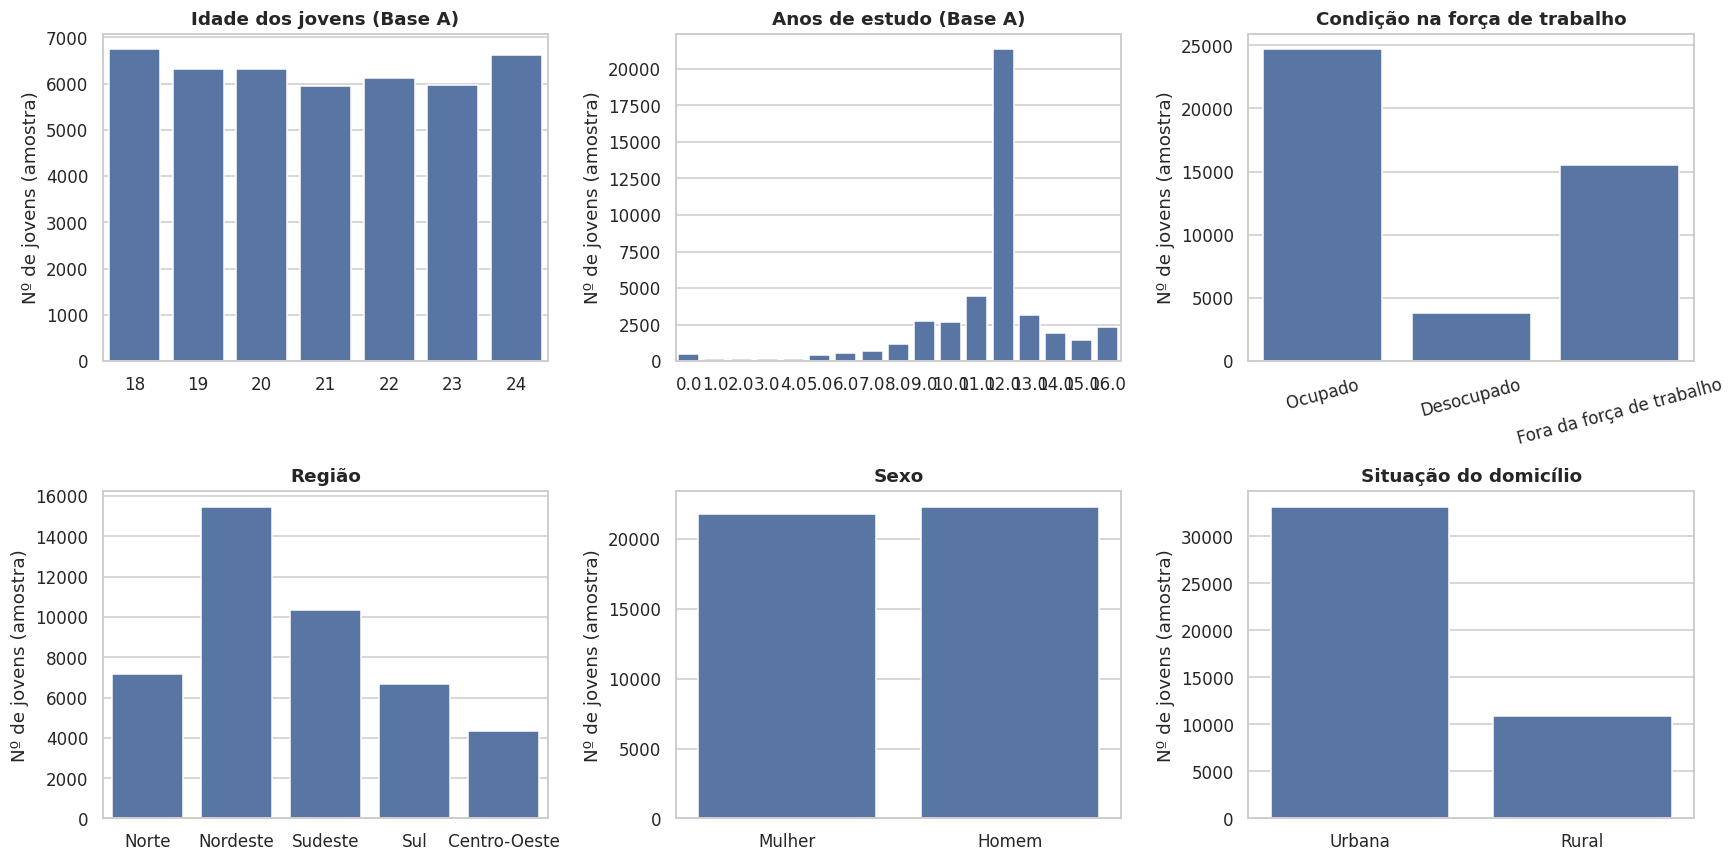

In [11]:
def tabela_cat(base, col):
    g = base.groupby(col, observed=True)
    t = pd.DataFrame({"n": g.size(), "peso": g["peso"].sum()})
    t["% amostra"] = t["n"] / t["n"].sum() * 100
    t["% ponderado (população)"] = t["peso"] / t["peso"].sum() * 100
    return t[["n", "% amostra", "% ponderado (população)"]].round(1)

for col, titulo in [("sexo", "Sexo"), ("situacao", "Situação do domicílio"), ("regiao", "Região"),
                    ("status_ocupacao", "Condição na força de trabalho"), ("faixa_escolaridade", "Faixa de escolaridade")]:
    print(f"\n{titulo} — Base A")
    t = tabela_cat(base_A, col)
    display(t)
    salvar_tab(t, f"etapa3_perfil_{col}")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(data=base_A, x="idade", color="#4C72B0", ax=axes[0, 0]); axes[0, 0].set_title("Idade dos jovens (Base A)")
sns.countplot(data=base_A, x="anos_estudo", color="#4C72B0", ax=axes[0, 1]); axes[0, 1].set_title("Anos de estudo (Base A)")
sns.countplot(data=base_A, x="status_ocupacao", order=["Ocupado", "Desocupado", "Fora da força de trabalho"], color="#4C72B0", ax=axes[0, 2])
axes[0, 2].set_title("Condição na força de trabalho"); axes[0, 2].tick_params(axis="x", rotation=15)
sns.countplot(data=base_A, x="regiao", color="#4C72B0", ax=axes[1, 0]); axes[1, 0].set_title("Região")
sns.countplot(data=base_A, x="sexo", color="#4C72B0", ax=axes[1, 1]); axes[1, 1].set_title("Sexo")
sns.countplot(data=base_A, x="situacao", color="#4C72B0", ax=axes[1, 2]); axes[1, 2].set_title("Situação do domicílio")
for ax in axes.ravel():
    ax.set_ylabel("Nº de jovens (amostra)")
    ax.set_xlabel("")
salvar_fig("etapa3_perfil_jovens")

,rendimento (R$)
count,23716.000000
mean,1703.650000
std,1431.540000
min,20.000000
1%,150.000000
5%,400.000000
25%,1200.000000
50%,1412.000000
75%,2000.000000
95%,3500.000000


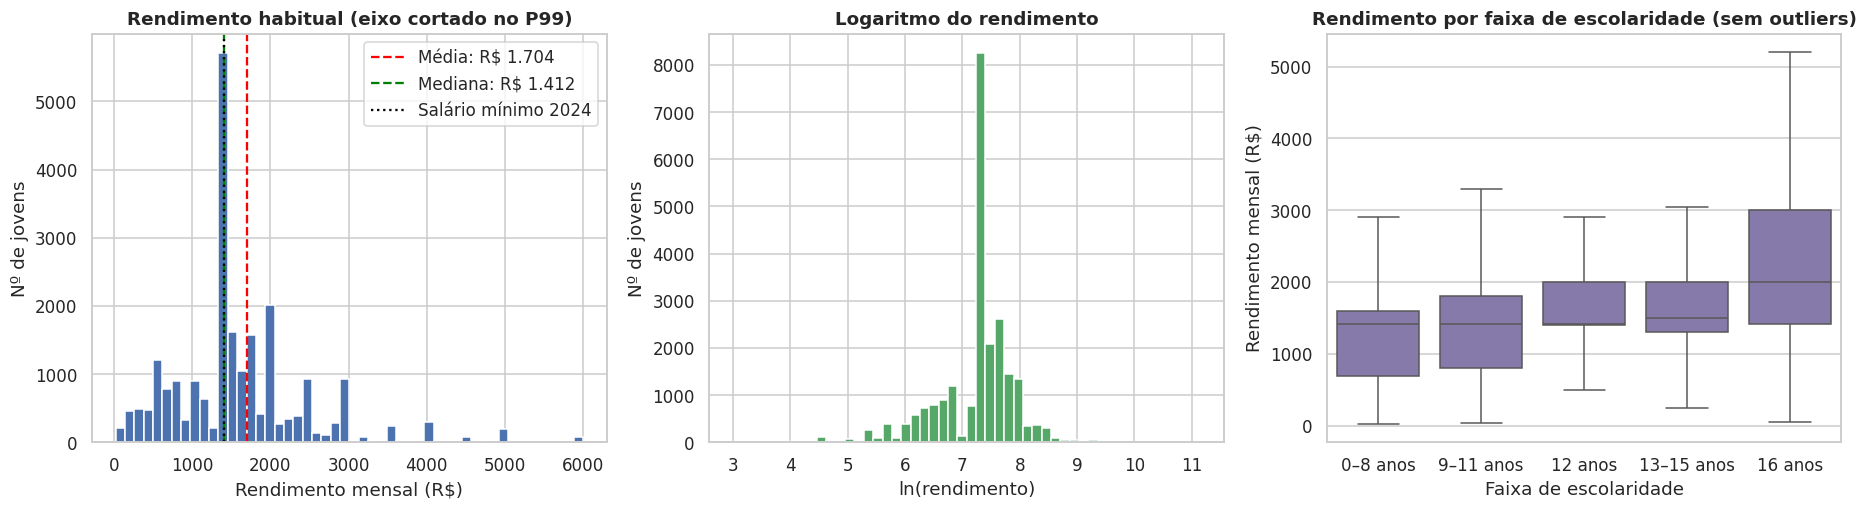

,n,média (R$),mediana (R$),desvio padrão (R$),média ponderada (R$)
faixa_escolaridade,,,,,
0–8 anos,1704,1330.40,1412.0,961.10,1450.83
9–11 anos,4286,1440.61,1412.0,998.38,1517.58
12 anos,12458,1662.05,1412.0,1264.36,1744.86
13–15 anos,3665,1852.00,1500.0,1404.29,1940.83
16 anos,1603,2787.81,2000.0,2859.09,3024.21


In [12]:
# --- Rendimento (Base B) ---
r = base_B["rendimento"]
p99 = r.quantile(0.99)
q1, q3 = r.quantile([.25, .75])
limite_iqr = q3 + 1.5 * (q3 - q1)

desc = r.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("rendimento (R$)").round(2)
desc.loc["assimetria"] = stats.skew(r)
desc.loc["curtose (excesso)"] = stats.kurtosis(r)
desc.loc["coef. de variação"] = r.std() / r.mean()
desc.loc["média ponderada"] = np.average(r, weights=base_B["peso"])
display(desc)
salvar_tab(desc, "etapa3_rendimento_descritivas")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].hist(r[r <= p99], bins=50, color="#4C72B0", edgecolor="white")
axes[0].axvline(r.mean(), color="red", ls="--", label=f"Média: {brl(r.mean(), 0)}")
axes[0].axvline(r.median(), color="green", ls="--", label=f"Mediana: {brl(r.median(), 0)}")
axes[0].axvline(SALARIO_MINIMO_2024, color="black", ls=":", label="Salário mínimo 2024")
axes[0].set_title("Rendimento habitual (eixo cortado no P99)"); axes[0].set_xlabel("Rendimento mensal (R$)"); axes[0].set_ylabel("Nº de jovens"); axes[0].legend()
axes[1].hist(base_B["log_rendimento"], bins=50, color="#55A868", edgecolor="white")
axes[1].set_title("Logaritmo do rendimento"); axes[1].set_xlabel("ln(rendimento)"); axes[1].set_ylabel("Nº de jovens")
sns.boxplot(data=base_B, x="faixa_escolaridade", y="rendimento", showfliers=False, color="#8172B2", ax=axes[2])
axes[2].set_title("Rendimento por faixa de escolaridade (sem outliers)"); axes[2].set_xlabel("Faixa de escolaridade"); axes[2].set_ylabel("Rendimento mensal (R$)")
salvar_fig("etapa3_rendimento")

# --- Rendimento por faixa de escolaridade ---
g = base_B.groupby("faixa_escolaridade", observed=True)
rend_faixa = pd.DataFrame({
    "n": g.size(),
    "média (R$)": g["rendimento"].mean(),
    "mediana (R$)": g["rendimento"].median(),
    "desvio padrão (R$)": g["rendimento"].std(),
})
rend_faixa["média ponderada (R$)"] = (base_B["rendimento"] * base_B["peso"]).groupby(base_B["faixa_escolaridade"], observed=True).sum() / g["peso"].sum()
rend_faixa = rend_faixa.round(2)
display(rend_faixa)
salvar_tab(rend_faixa, "etapa3_rendimento_por_faixa")

,n (força de trabalho),ocupados,desocupados,taxa de ocupação (%),taxa de ocupação ponderada (%)
faixa_escolaridade,,,,,
0–8 anos,2150,1832,318,85.21,83.97
9–11 anos,5345,4548,797,85.09,84.80
12 anos,14996,12898,2098,86.01,86.82
13–15 anos,4184,3767,417,90.03,90.83
16 anos,1804,1637,167,90.74,90.38


Qui-quadrado = 88,05, gl = 4, p-valor < 0,0001, V de Cramér = 0,056


status_ocupacao,Ocupado,Desocupado,Fora da força de trabalho
faixa_escolaridade,,,
0–8 anos,45.9,8.0,46.1
9–11 anos,46.2,8.1,45.7
12 anos,60.4,9.8,29.7
13–15 anos,57.6,6.4,36.0
16 anos,70.7,7.2,22.1


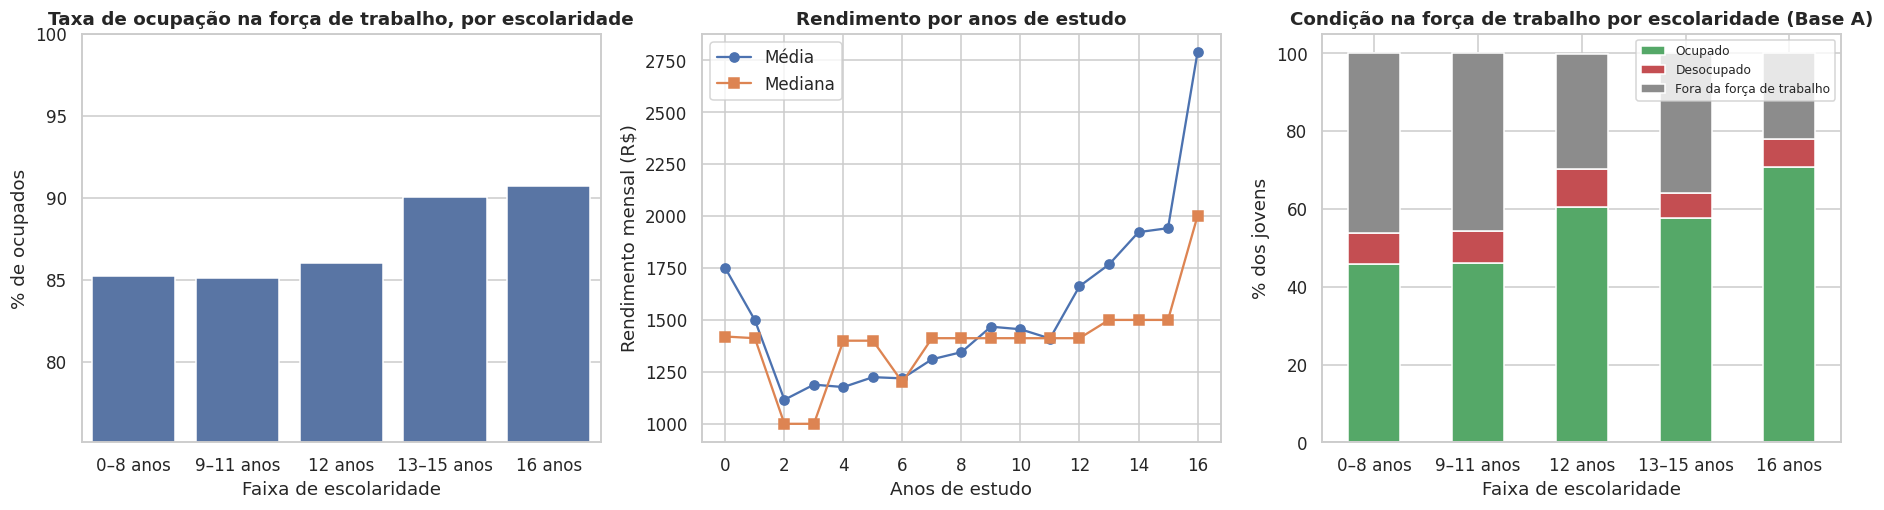

In [13]:
# --- Ocupação por escolaridade (Base C: força de trabalho) ---
gC = base_C.groupby("faixa_escolaridade", observed=True)
taxa = pd.DataFrame({"n (força de trabalho)": gC.size(), "ocupados": gC["ocupado_binario"].sum()})
taxa["desocupados"] = taxa["n (força de trabalho)"] - taxa["ocupados"]
taxa["taxa de ocupação (%)"] = taxa["ocupados"] / taxa["n (força de trabalho)"] * 100
taxa["taxa de ocupação ponderada (%)"] = ((base_C["ocupado_binario"] * base_C["peso"]).groupby(base_C["faixa_escolaridade"], observed=True).sum()
                                          / gC["peso"].sum() * 100)
taxa = taxa.round(2)
display(taxa)
salvar_tab(taxa, "etapa3_taxa_ocupacao_por_faixa")

tab_cont = pd.crosstab(base_C["faixa_escolaridade"], base_C["ocupado_binario"])
chi2, p_chi2, gl_chi2, _ = stats.chi2_contingency(tab_cont)
cramer_v = np.sqrt(chi2 / (tab_cont.values.sum() * (min(tab_cont.shape) - 1)))
print(f"Qui-quadrado = {num(chi2)}, gl = {gl_chi2}, p-valor {pval(p_chi2)}, V de Cramér = {num(cramer_v, 3)}")

# --- Status por escolaridade (Base A): quanto fica fora da força de trabalho ---
status_faixa = pd.crosstab(base_A["faixa_escolaridade"], base_A["status_ocupacao"], normalize="index") * 100
status_faixa = status_faixa[["Ocupado", "Desocupado", "Fora da força de trabalho"]].round(1)
display(status_faixa)
salvar_tab(status_faixa, "etapa3_status_por_faixa")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.barplot(x=taxa.index.astype(str), y=taxa["taxa de ocupação (%)"], color="#4C72B0", ax=axes[0])
axes[0].set_title("Taxa de ocupação na força de trabalho, por escolaridade"); axes[0].set_xlabel("Faixa de escolaridade"); axes[0].set_ylabel("% de ocupados")
axes[0].set_ylim(max(0, taxa["taxa de ocupação (%)"].min() - 10), 100)
medias_ano = base_B.groupby("anos_estudo")["rendimento"].agg(["mean", "median"])
axes[1].plot(medias_ano.index, medias_ano["mean"], marker="o", label="Média")
axes[1].plot(medias_ano.index, medias_ano["median"], marker="s", label="Mediana")
axes[1].set_title("Rendimento por anos de estudo"); axes[1].set_xlabel("Anos de estudo"); axes[1].set_ylabel("Rendimento mensal (R$)"); axes[1].legend()
status_faixa.plot(kind="bar", stacked=True, ax=axes[2], color=["#55A868", "#C44E52", "#8C8C8C"])
axes[2].set_title("Condição na força de trabalho por escolaridade (Base A)"); axes[2].set_xlabel("Faixa de escolaridade"); axes[2].set_ylabel("% dos jovens"); axes[2].tick_params(axis="x", rotation=0); axes[2].legend(fontsize=8)
salvar_fig("etapa3_ocupacao_rendimento_escolaridade")

In [14]:
r = base_B["rendimento"]
assim = stats.skew(r)
ate_sm = (r <= SALARIO_MINIMO_2024).mean()
t0, t1 = taxa["taxa de ocupação (%)"].iloc[0], taxa["taxa de ocupação (%)"].iloc[-1]
m0, m1 = rend_faixa["mediana (R$)"].iloc[0], rend_faixa["mediana (R$)"].iloc[-1]
fora0, fora1 = status_faixa["Fora da força de trabalho"].iloc[0], status_faixa["Fora da força de trabalho"].iloc[-1]
mono_ocup = taxa["taxa de ocupação (%)"].is_monotonic_increasing
mono_rend = rend_faixa["mediana (R$)"].is_monotonic_increasing


def _brl_seguro(valor, decimais=2):
    """Formata em BRL escapando '$' para evitar conflito com LaTeX/MathJax."""
    return brl(valor, decimais).replace("$", r"\$")


linhas = [
    f"**Perfil:** {pct((base_A['sexo']=='Mulher').mean())} da amostra são mulheres, {pct((base_A['situacao']=='Urbana').mean())} moram em área urbana e a região mais representada é {base_A['regiao'].value_counts().idxmax()} ({pct(base_A['regiao'].value_counts(normalize=True).max())}).",
    f"**Rendimento:** média de {_brl_seguro(r.mean())} e mediana de {_brl_seguro(r.median())}. A média é {num((r.mean()/r.median()-1)*100, 1)}% {'maior' if r.mean() > r.median() else 'menor'} que a mediana, e a assimetria é {num(assim, 2)} — {'distribuição fortemente assimétrica à direita, o que já antecipa que a hipótese de normalidade será frágil (Etapa 4)' if assim > 1 else 'assimetria moderada'}.",
    f"**{pct(ate_sm)}** dos jovens ocupados recebem até um salário mínimo ({_brl_seguro(SALARIO_MINIMO_2024, 0)}).",
    f"**Ocupação × escolaridade (H1-A):** a taxa de ocupação na força de trabalho vai de {num(t0, 1)}% (faixa {taxa.index[0]}) a {num(t1, 1)}% (faixa {taxa.index[-1]}); {'ela cresce de forma monotônica entre as faixas' if mono_ocup else 'ela não cresce de forma monotônica entre as faixas, o que deve ser lido com cuidado'}. Qui-quadrado: p {pval(p_chi2)}, V de Cramér = {num(cramer_v, 3)} ({'efeito pequeno' if cramer_v < 0.1 else 'efeito pequeno a moderado' if cramer_v < 0.3 else 'efeito moderado a grande'}).",
    f"**Rendimento × escolaridade (H1-B):** a mediana vai de {_brl_seguro(m0, 0)} (faixa {rend_faixa.index[0]}) a {_brl_seguro(m1, 0)} (faixa {rend_faixa.index[-1]}), uma razão de {num(m1/m0, 2)}×; {'ela cresce monotonicamente entre as faixas' if mono_rend else 'ela não cresce monotonicamente entre as faixas'}.",
    f"**Atenção — seleção:** a parcela fora da força de trabalho vai de {num(fora0, 1)}% na faixa {status_faixa.index[0]} a {num(fora1, 1)}% na faixa {status_faixa.index[-1]}. A taxa de ocupação da Base C ignora esse grupo, então não descreve todos os jovens com cada nível de escolaridade.",
    "Estes são resultados **descritivos** e sem controle de outras variáveis; os modelos das Etapas 6 a 8 refinam a leitura.",
]

relatar("Relatório da Análise Exploratória", linhas)
RES.update(
    taxa_ocup_faixa=taxa,
    rend_faixa=rend_faixa,
    p_chi2=p_chi2,
    cramer_v=cramer_v,
    razao_mediana=m1 / m0,
)

### Relatório da Análise Exploratória

- **Perfil:** 49,4% da amostra são mulheres, 75,2% moram em área urbana e a região mais representada é Nordeste (35,1%).
- **Rendimento:** média de R\$ 1.703,65 e mediana de R\$ 1.412,00. A média é 20,7% maior que a mediana, e a assimetria é 12,03 — distribuição fortemente assimétrica à direita, o que já antecipa que a hipótese de normalidade será frágil (Etapa 4).
- **50,2%** dos jovens ocupados recebem até um salário mínimo (R\$ 1.412).
- **Ocupação × escolaridade (H1-A):** a taxa de ocupação na força de trabalho vai de 85,2% (faixa 0–8 anos) a 90,7% (faixa 16 anos); ela não cresce de forma monotônica entre as faixas, o que deve ser lido com cuidado. Qui-quadrado: p < 0,0001, V de Cramér = 0,056 (efeito pequeno).
- **Rendimento × escolaridade (H1-B):** a mediana vai de R\$ 1.412 (faixa 0–8 anos) a R\$ 2.000 (faixa 16 anos), uma razão de 1,42×; ela cresce monotonicamente entre as faixas.
- **Atenção — seleção:** a parcela fora da força de trabalho vai de 46,1% na faixa 0–8 anos a 22,1% na faixa 16 anos. A taxa de ocupação da Base C ignora esse grupo, então não descreve todos os jovens com cada nível de escolaridade.
- Estes são resultados **descritivos** e sem controle de outras variáveis; os modelos das Etapas 6 a 8 refinam a leitura.

---
# Etapa 4 — Distribuição Normal de Probabilidade

Assumindo que o rendimento segue uma distribuição Normal, calcular (a) $P(X < \bar{x})$ e (b) $P(X > Md)$ para classificar cada evento.

1. **Variável: rendimento mensal habitual (Base B).** É a variável contínua central do problema, a mesma usada nos testes e nas regressões, o que mantém o projeto coerente.
2. **Parâmetros da Normal estimados com os dados:** $\mu = \bar{x}$ e $\sigma$ = desvio padrão **populacional** (`ddof=0`). Tratamos os registros da base como a população de referência do exercício, o que também está de acordo com o enunciado do Item 03 ("desvio padrão populacional dos dados"). Usar o desvio amostral (`ddof=1`) mudaria o resultado apenas na quinta casa decimal.
3. **Cálculo pela padronização:** $Z = (x-\mu)/\sigma$ e consulta à função de distribuição acumulada $\Phi$.
4. **Classificação do evento** pela convenção: 0 = impossível; entre 0 e 0,5 = improvável; 0,5 = equiprovável; entre 0,5 e 1 = provável; 1 = certo. Se a disciplina adotar outra convenção, basta ajustar a função `classificar_prob` na célula de configuração.
5. **Comparar o resultado teórico com a frequência observada.** A pergunta pede o resultado *sob a hipótese de normalidade*. Mas, como essa hipótese é discutível para rendimentos, o notebook também mostra a proporção real de jovens abaixo da média e acima da mediana, além de testes de normalidade e gráficos (histograma, curva ajustada e Q-Q plot). Assim a classificação fica acompanhada de uma avaliação honesta do quanto o modelo normal descreve os dados.


Parâmetros: média (μ) = R$ 1.703,65 | desvio padrão (σ) = R$ 1.431,51 | mediana = R$ 1.412,00 | n = 23.716


,Evento,Valor de referência (R$),Z,Probabilidade (Normal),Classificação,Proporção observada nos dados
0,(a) P(X < média),1703.6482,0.0000,0.5000,Evento equiprovável (≈ 50%),0.6530
1,(b) P(X > mediana),1412.0000,-0.2037,0.5807,Evento provável (> 50%),0.4975


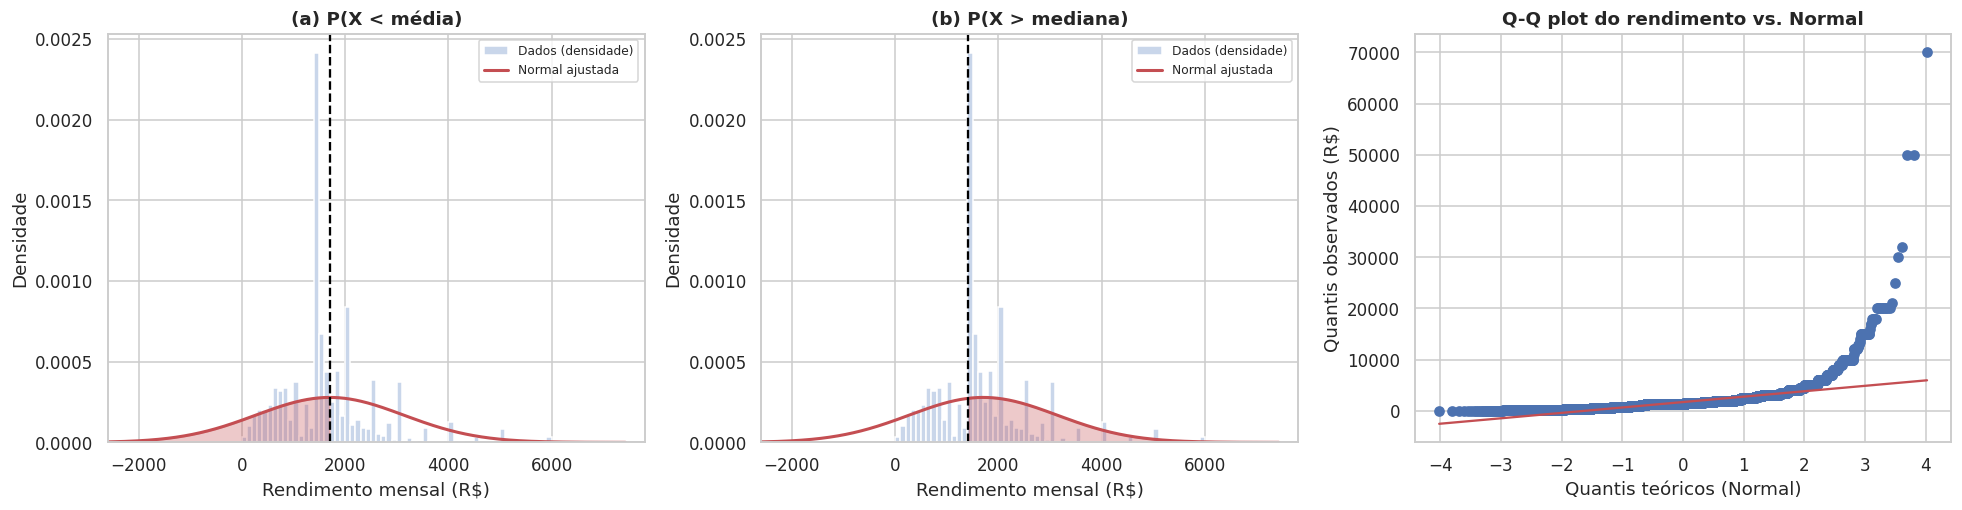

Assimetria = 12,033 | Curtose (excesso) = 372,423
Shapiro-Wilk (amostra de 5.000): W = 0,4091, p < 0,0001
D'Agostino-Pearson (base completa): K² = 41.613,77, p < 0,0001


In [15]:
x = base_B["rendimento"]
mu, sigma, md_ = x.mean(), x.std(ddof=0), x.median()

# (a) P(X < média)
z_a = (mu - mu) / sigma
p_a = stats.norm.cdf(z_a)
# (b) P(X > mediana)
z_b = (md_ - mu) / sigma
p_b = 1 - stats.norm.cdf(z_b)

emp_a = (x < mu).mean()
emp_b = (x > md_).mean()
p_neg = stats.norm.cdf(0, loc=mu, scale=sigma)       # massa que a Normal atribui a rendimentos negativos

tab_normal = pd.DataFrame({
    "Evento": ["(a) P(X < média)", "(b) P(X > mediana)"],
    "Valor de referência (R$)": [mu, md_],
    "Z": [z_a, z_b],
    "Probabilidade (Normal)": [p_a, p_b],
    "Classificação": [classificar_prob(p_a), classificar_prob(p_b)],
    "Proporção observada nos dados": [emp_a, emp_b],
})
print(f"Parâmetros: média (μ) = {brl(mu)} | desvio padrão (σ) = {brl(sigma)} | mediana = {brl(md_)} | n = {inteiro(len(x))}")
display(tab_normal.round(4))
salvar_tab(tab_normal.round(6), "etapa4_probabilidades_normal", index=False)

# ---- gráficos ----
p99 = x.quantile(0.99)
bins = np.linspace(0, p99, 61); larg = bins[1] - bins[0]
xs = np.linspace(mu - 3 * sigma, mu + 4 * sigma, 800)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (lim, lado, titulo) in zip(axes[:2], [(mu, "esq", "(a) P(X < média)"), (md_, "dir", "(b) P(X > mediana)")]):
    ax.hist(x, bins=bins, weights=np.ones(len(x)) / len(x) / larg, color="#C9D6EA", edgecolor="white", label="Dados (densidade)")
    ax.plot(xs, stats.norm.pdf(xs, mu, sigma), color="#C44E52", lw=2, label="Normal ajustada")
    mascara = xs <= lim if lado == "esq" else xs >= lim
    ax.fill_between(xs[mascara], stats.norm.pdf(xs[mascara], mu, sigma), color="#C44E52", alpha=.3)
    ax.axvline(lim, color="black", ls="--")
    ax.set_xlim(min(xs.min(), -sigma), p99 * 1.3)
    ax.set_title(titulo); ax.set_xlabel("Rendimento mensal (R$)"); ax.set_ylabel("Densidade"); ax.legend(fontsize=8)
stats.probplot(x, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot do rendimento vs. Normal"); axes[2].set_xlabel("Quantis teóricos (Normal)"); axes[2].set_ylabel("Quantis observados (R$)")
salvar_fig("etapa4_normal")

# ---- testes de normalidade ----
amostra_sw = x.sample(min(5000, len(x)), random_state=SEED)
sw_stat, sw_p = stats.shapiro(amostra_sw)
k2_stat, k2_p = stats.normaltest(x)
print(f"Assimetria = {num(stats.skew(x), 3)} | Curtose (excesso) = {num(stats.kurtosis(x), 3)}")
print(f"Shapiro-Wilk (amostra de {inteiro(len(amostra_sw))}): W = {num(sw_stat, 4)}, p {pval(sw_p)}")
print(f"D'Agostino-Pearson (base completa): K² = {num(k2_stat, 2)}, p {pval(k2_p)}")

In [16]:
assim = stats.skew(x)
linhas = [
    f"Sob a hipótese de normalidade (μ = {brl(mu)}, σ = {brl(sigma)}):",
    f"**(a) P(X < média) = {pct(p_a, 2)}** (Z = {num(z_a, 2)}) → **{classificar_prob(p_a)}**. Por construção, a média é o centro da Normal, então esse resultado é exatamente 50% e independe dos dados.",
    f"**(b) P(X > mediana) = {pct(p_b, 2)}** (Z = {num(z_b, 3)}) → **{classificar_prob(p_b)}**. {'Como a mediana é menor que a média, a Normal atribui mais da metade da probabilidade à região acima da mediana.' if md_ < mu else 'Como a mediana é maior ou igual à média, a probabilidade fica em torno de 50% ou abaixo.'}",
    f"**Quão boa é a hipótese de normalidade?** Nos dados reais, {pct(emp_a)} dos jovens ganham menos que a média (a Normal prevê 50%) e {pct(emp_b)} ganham mais que a mediana (por definição, cerca de 50%). A diferença entre o previsto e o observado mostra o efeito da assimetria ({num(assim, 2)}).",
    f"A Normal ajustada atribui **{pct(p_neg, 1)}** de probabilidade a rendimentos **negativos**, o que é impossível para este fenômeno — mais um sinal de que ela é apenas uma aproximação.",
    f"Os testes de normalidade {'**rejeitam**' if (sw_p < 0.05 or k2_p < 0.05) else 'não rejeitam'} a hipótese de que o rendimento é Normal (Shapiro-Wilk p {pval(sw_p)}; D'Agostino-Pearson p {pval(k2_p)}). O Q-Q plot confirma visualmente o afastamento nas caudas.",
    "**Conclusão metodológica:** as probabilidades pedidas foram calculadas e classificadas conforme o enunciado, mas devem ser lidas como resultado de um **modelo simplificador**. Isso será considerado nas limitações dos testes de média (Etapa 5) e das regressões (Etapas 6 e 7).",
]
relatar("Relatório", linhas)
RES.update(mu=mu, sigma=sigma, mediana=md_, p_a=p_a, p_b=p_b, class_a=classificar_prob(p_a), class_b=classificar_prob(p_b), emp_a=emp_a, emp_b=emp_b)

### Relatório

- Sob a hipótese de normalidade (μ = R$ 1.703,65, σ = R$ 1.431,51):
- **(a) P(X < média) = 50,00%** (Z = 0,00) → **Evento equiprovável (≈ 50%)**. Por construção, a média é o centro da Normal, então esse resultado é exatamente 50% e independe dos dados.
- **(b) P(X > mediana) = 58,07%** (Z = -0,204) → **Evento provável (> 50%)**. Como a mediana é menor que a média, a Normal atribui mais da metade da probabilidade à região acima da mediana.
- **Quão boa é a hipótese de normalidade?** Nos dados reais, 65,3% dos jovens ganham menos que a média (a Normal prevê 50%) e 49,8% ganham mais que a mediana (por definição, cerca de 50%). A diferença entre o previsto e o observado mostra o efeito da assimetria (12,03).
- A Normal ajustada atribui **11,7%** de probabilidade a rendimentos **negativos**, o que é impossível para este fenômeno — mais um sinal de que ela é apenas uma aproximação.
- Os testes de normalidade **rejeitam** a hipótese de que o rendimento é Normal (Shapiro-Wilk p < 0,0001; D'Agostino-Pearson p < 0,0001). O Q-Q plot confirma visualmente o afastamento nas caudas.
- **Conclusão metodológica:** as probabilidades pedidas foram calculadas e classificadas conforme o enunciado, mas devem ser lidas como resultado de um **modelo simplificador**. Isso será considerado nas limitações dos testes de média (Etapa 5) e das regressões (Etapas 6 e 7).

---
# Etapa 5 — Testes de hipóteses para a média

Realizar dois testes Z unilaterais para a média do rendimento: (a) cauda à esquerda, $\alpha = 6\%$, $n = 20$; (b) cauda à direita, $\alpha = 9\%$, $n = 25$.

1. **Contextos definidos antes de olhar os resultados** (conforme a proposta do projeto), para evitar escolher a hipótese depois de ver qual dá "significativo":
   - **Teste A:** o rendimento dos jovens ocupados do **Nordeste** é *menor* que o das demais regiões? $H_0: \mu_{NE} \geq \mu_{ref}$ vs. $H_1: \mu_{NE} < \mu_{ref}$.
   - **Teste B:** o rendimento dos jovens ocupados do **Sudeste** é *maior* que o das demais regiões? $H_0: \mu_{SE} \leq \mu_{ref}$ vs. $H_1: \mu_{SE} > \mu_{ref}$.
2. **População de referência = jovens ocupados de todas as outras regiões.** Isso dá uma comparação com sentido de política pública (região vs. resto do país) e evita comparar a amostra com ela mesma.
3. **$\mu_{ref}$ e $\sigma_{ref}$ calculados na população de referência:** média e desvio padrão **populacional** (`ddof=0`) dos jovens das demais regiões, conforme o enunciado ("desvio padrão populacional dos dados"). Como o σ é tomado como conhecido, o teste apropriado é o **Z**.
4. **Amostras aleatórias simples sem reposição, com semente fixa** (`random_state = 42`), de tamanho 20 e 25 exatamente como pedido.
5. **Decisão pelo p-valor**: rejeita-se $H_0$ se p-valor $< \alpha$. O valor crítico de Z também é mostrado.
6. **Análises complementares (sem substituir o teste pedido):**
   - *Repetição do sorteio 2.000 vezes*: com $n$ tão pequeno, a decisão de uma única amostra depende muito da sorte. A fração de vezes em que $H_0$ é rejeitada mostra o quanto a conclusão é estável.
   - *Variante com referência global* (média e desvio padrão de **toda** a Base B): trata a leitura literal do enunciado, em que a referência é "a média populacional dos dados".
   - *Comparação com a diferença real* entre as médias dos grupos na base completa, para dar contexto ao resultado da amostra pequena.
7. **Limitação a ser explicitada:** o Teste Z supõe amostra aleatória simples e (aproximadamente) distribuição normal da média amostral. Rendimentos são assimétricos e $n$ = 20/25 é pequeno para o Teorema Central do Limite compensar totalmente; além disso, a PNAD é uma amostra complexa (pesos, estratos, conglomerados).

,n,média amostral (R$),μ referência (R$),σ referência (R$),erro padrão (R$),Z calculado,Z crítico,p-valor,α,decisão
"Teste A — Nordeste < demais (α = 6%, n = 20)",20,941.00,1898.3597,1559.3489,348.681,-2.7457,-1.5548,0.0030,0.06,Rejeita H0
"Teste B — Sudeste > demais (α = 9%, n = 25)",25,2033.68,1653.1402,1408.4600,281.692,1.3509,1.3408,0.0884,0.09,Rejeita H0


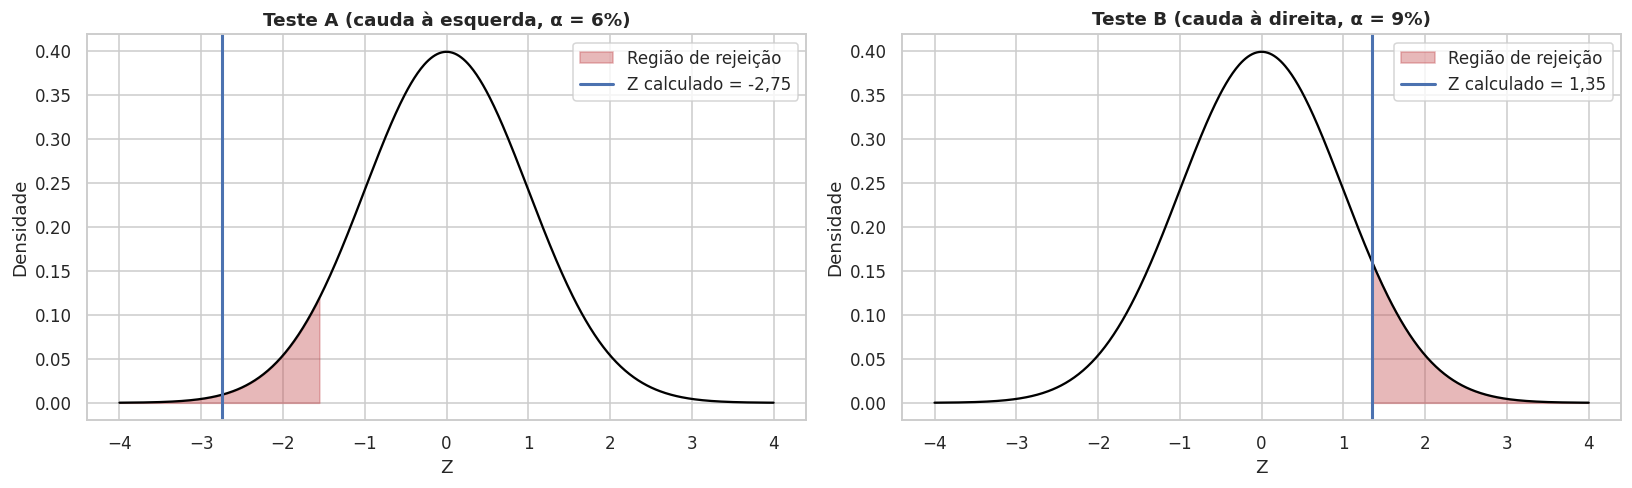

In [17]:
def teste_z_media(amostra, mu_ref, sigma_ref, alpha, cauda):
    n = len(amostra)
    xbar = amostra.mean()
    erro_padrao = sigma_ref / np.sqrt(n)
    z = (xbar - mu_ref) / erro_padrao
    if cauda == "esquerda":
        p, z_crit = stats.norm.cdf(z), stats.norm.ppf(alpha)
    else:
        p, z_crit = stats.norm.sf(z), stats.norm.ppf(1 - alpha)
    return {"n": n, "média amostral (R$)": xbar, "μ referência (R$)": mu_ref, "σ referência (R$)": sigma_ref,
            "erro padrão (R$)": erro_padrao, "Z calculado": z, "Z crítico": z_crit, "p-valor": p,
            "α": alpha, "decisão": "Rejeita H0" if p < alpha else "Não rejeita H0"}

def monte_carlo(valores, n, mu_ref, sigma_ref, alpha, cauda, reps=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    v = np.asarray(valores)
    idx = np.array([rng.choice(len(v), n, replace=False) for _ in range(reps)])
    z = (v[idx].mean(axis=1) - mu_ref) / (sigma_ref / np.sqrt(n))
    p = stats.norm.cdf(z) if cauda == "esquerda" else stats.norm.sf(z)
    return (p < alpha).mean()

# ---------- definição dos grupos ----------
ne = base_B.loc[base_B["regiao"] == "Nordeste", "rendimento"]
ne_ref = base_B.loc[base_B["regiao"] != "Nordeste", "rendimento"]
se = base_B.loc[base_B["regiao"] == "Sudeste", "rendimento"]
se_ref = base_B.loc[base_B["regiao"] != "Sudeste", "rendimento"]

amostra_A = ne.sample(20, random_state=SEED)
amostra_B = se.sample(25, random_state=SEED)

# ---------- testes principais ----------
res_A = teste_z_media(amostra_A, ne_ref.mean(), ne_ref.std(ddof=0), 0.06, "esquerda")
res_B = teste_z_media(amostra_B, se_ref.mean(), se_ref.std(ddof=0), 0.09, "direita")

tab_testes = pd.DataFrame({"Teste A — Nordeste < demais (α = 6%, n = 20)": res_A,
                           "Teste B — Sudeste > demais (α = 9%, n = 25)": res_B}).T
display(tab_testes.assign(**{c: tab_testes[c].astype(float).round(4) for c in
        ["média amostral (R$)", "μ referência (R$)", "σ referência (R$)", "erro padrão (R$)", "Z calculado", "Z crítico", "p-valor"]}))
salvar_tab(tab_testes, "etapa5_testes_z")

# ---------- gráfico das regiões de rejeição ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, res, cauda, titulo in [(axes[0], res_A, "esquerda", "Teste A (cauda à esquerda, α = 6%)"),
                               (axes[1], res_B, "direita", "Teste B (cauda à direita, α = 9%)")]:
    zs = np.linspace(-4, 4, 600)
    ax.plot(zs, stats.norm.pdf(zs), color="black")
    rej = zs <= res["Z crítico"] if cauda == "esquerda" else zs >= res["Z crítico"]
    ax.fill_between(zs[rej], stats.norm.pdf(zs[rej]), color="#C44E52", alpha=.4, label="Região de rejeição")
    ax.axvline(res["Z calculado"], color="#4C72B0", lw=2, label=f"Z calculado = {num(res['Z calculado'], 2)}")
    ax.set_title(titulo); ax.set_xlabel("Z"); ax.set_ylabel("Densidade"); ax.legend()
salvar_fig("etapa5_regioes_rejeicao")

In [18]:
# ---------- análises complementares ----------
mu_glob, sd_glob = base_B["rendimento"].mean(), base_B["rendimento"].std(ddof=0)

res_A_glob = teste_z_media(amostra_A, mu_glob, sd_glob, 0.06, "esquerda")
res_B_glob = teste_z_media(amostra_B, mu_glob, sd_glob, 0.09, "direita")

mc_A = monte_carlo(ne, 20, ne_ref.mean(), ne_ref.std(ddof=0), 0.06, "esquerda")
mc_B = monte_carlo(se, 25, se_ref.mean(), se_ref.std(ddof=0), 0.09, "direita")

compl = pd.DataFrame([
    ["A — Nordeste < demais", ne.mean(), ne_ref.mean(), ne.mean() - ne_ref.mean(), res_A["p-valor"], res_A["decisão"], mc_A,
     res_A_glob["p-valor"], res_A_glob["decisão"]],
    ["B — Sudeste > demais", se.mean(), se_ref.mean(), se.mean() - se_ref.mean(), res_B["p-valor"], res_B["decisão"], mc_B,
     res_B_glob["p-valor"], res_B_glob["decisão"]],
], columns=["Teste", "média do grupo (base completa)", "média da referência", "diferença real (R$)", "p-valor (amostra)", "decisão (amostra)",
            "% de rejeição em 2.000 sorteios", "p-valor (ref. global)", "decisão (ref. global)"])
display(compl.round(4))
salvar_tab(compl.round(6), "etapa5_complementares", index=False)

linhas = [
    f"**Teste A (Nordeste < demais regiões; α = 6%; n = 20):** média amostral de {brl(res_A['média amostral (R$)'])} contra referência de {brl(res_A['μ referência (R$)'])}; Z = {num(res_A['Z calculado'], 3)} (crítico {num(res_A['Z crítico'], 3)}); p-valor {pval(res_A['p-valor'])}. **{res_A['decisão']}** ao nível de 6%.",
    f"**Teste B (Sudeste > demais regiões; α = 9%; n = 25):** média amostral de {brl(res_B['média amostral (R$)'])} contra referência de {brl(res_B['μ referência (R$)'])}; Z = {num(res_B['Z calculado'], 3)} (crítico {num(res_B['Z crítico'], 3)}); p-valor {pval(res_B['p-valor'])}. **{res_B['decisão']}** ao nível de 9%.",
    f"**Contexto real:** na base completa, o rendimento médio do Nordeste é {brl(abs(compl.loc[0, 'diferença real (R$)']))} {'menor' if compl.loc[0, 'diferença real (R$)'] < 0 else 'maior'} que o das demais regiões, e o do Sudeste é {brl(abs(compl.loc[1, 'diferença real (R$)']))} {'maior' if compl.loc[1, 'diferença real (R$)'] > 0 else 'menor'}.",
    f"**Estabilidade da decisão:** repetindo o sorteio 2.000 vezes, $H_0$ é rejeitada em {pct(mc_A)} das amostras no Teste A e em {pct(mc_B)} no Teste B. {'Valores intermediários indicam que a conclusão de uma única amostra pequena é instável.' if (0.2 < mc_A < 0.8 or 0.2 < mc_B < 0.8) else 'Valores próximos dos extremos indicam que a conclusão da amostra é representativa do que se espera para esse tamanho amostral.'}",
    f"**Variante com referência global** (μ = {brl(mu_glob)}, σ = {brl(sd_glob)}): Teste A → {res_A_glob['decisão']} (p {pval(res_A_glob['p-valor'])}); Teste B → {res_B_glob['decisão']} (p {pval(res_B_glob['p-valor'])}). {'As decisões coincidem com as dos testes principais.' if (res_A_glob['decisão'] == res_A['decisão'] and res_B_glob['decisão'] == res_B['decisão']) else 'Ao menos uma decisão muda conforme a definição da referência, o que mostra sensibilidade a essa escolha metodológica.'}",
    "**Limitações:** (i) a amostra de 20–25 jovens é pequena e o rendimento é assimétrico; (ii) o desvio padrão de referência é tratado como conhecido; (iii) o teste ignora pesos, estratos e conglomerados da PNAD; (iv) 'não rejeitar $H_0$' **não prova** que as médias são iguais — indica apenas que a amostra não forneceu evidência suficiente contra $H_0$ ao nível escolhido.",
]
relatar("Relatório", linhas)
RES.update(teste_A=res_A, teste_B=res_B, mc_A=mc_A, mc_B=mc_B)

,Teste,média do grupo (base completa),média da referência,diferença real (R$),p-valor (amostra),decisão (amostra),% de rejeição em 2.000 sorteios,p-valor (ref. global),decisão (ref. global)
0,A — Nordeste < demais,1222.7522,1898.3597,-675.6075,0.0030,Rejeita H0,0.7800,0.0086,Rejeita H0
1,B — Sudeste > demais,1844.7958,1653.1402,191.6556,0.0884,Rejeita H0,0.1765,0.1245,Não rejeita H0


### Relatório

- **Teste A (Nordeste < demais regiões; α = 6%; n = 20):** média amostral de R$ 941,00 contra referência de R$ 1.898,36; Z = -2,746 (crítico -1,555); p-valor = 0,0030. **Rejeita H0** ao nível de 6%.
- **Teste B (Sudeste > demais regiões; α = 9%; n = 25):** média amostral de R$ 2.033,68 contra referência de R$ 1.653,14; Z = 1,351 (crítico 1,341); p-valor = 0,0884. **Rejeita H0** ao nível de 9%.
- **Contexto real:** na base completa, o rendimento médio do Nordeste é R$ 675,61 menor que o das demais regiões, e o do Sudeste é R$ 191,66 maior.
- **Estabilidade da decisão:** repetindo o sorteio 2.000 vezes, $H_0$ é rejeitada em 78,0% das amostras no Teste A e em 17,6% no Teste B. Valores intermediários indicam que a conclusão de uma única amostra pequena é instável.
- **Variante com referência global** (μ = R$ 1.703,65, σ = R$ 1.431,51): Teste A → Rejeita H0 (p = 0,0086); Teste B → Não rejeita H0 (p = 0,1245). Ao menos uma decisão muda conforme a definição da referência, o que mostra sensibilidade a essa escolha metodológica.
- **Limitações:** (i) a amostra de 20–25 jovens é pequena e o rendimento é assimétrico; (ii) o desvio padrão de referência é tratado como conhecido; (iii) o teste ignora pesos, estratos e conglomerados da PNAD; (iv) 'não rejeitar $H_0$' **não prova** que as médias são iguais — indica apenas que a amostra não forneceu evidência suficiente contra $H_0$ ao nível escolhido.

---
# Etapa 6 — Análise bivariada e regressão linear simples


Medir e modelar a relação entre **anos de estudo** ($X$) e **rendimento mensal habitual** ($Y$) entre jovens ocupados, cobrindo: dispersão, covariância, correlação de Pearson, gráfico de correlação, reta de regressão, adequação do modelo ($R^2$ e teste F) e previsão.

1. **$X$ = anos de estudo e $Y$ = rendimento**, na Base B. A direção segue a hipótese H1-B: a escolaridade é a variável explicativa.
2. **Dispersão com ruído visual (*jitter*).** Como anos de estudo só assume valores inteiros, os pontos se sobrepõem em colunas verticais. Um deslocamento aleatório pequeno no eixo X **apenas no gráfico** torna visível a densidade; os cálculos usam os valores originais. A média por ano de estudo é sobreposta para destacar a tendência.
3. **Eixo Y cortado no percentil 99,5 apenas no gráfico**, para que poucos rendimentos extremos não achatem a visualização. Nenhum dado é removido do modelo.
4. **Pearson e também Spearman.** Pearson mede associação *linear* e é sensível a valores extremos; Spearman (baseado em postos) é uma verificação de que a conclusão não depende de poucos extremos nem da forma exata da relação.
5. **Intervalo de confiança de Fisher para $r$**, para mostrar a incerteza da correlação.
6. **Teste F e teste t do coeficiente.** Em regressão simples, $F = t^2$ e os dois dão o mesmo p-valor bilateral. Como a hipótese é direcional (H1: $\beta_1 > 0$), o p-valor unilateral é reportado.
7. **$R^2$ interpretado com cuidado.** Um $R^2$ baixo não invalida o coeficiente: significa que a escolaridade sozinha explica pouco da variação do rendimento (que depende de muitos outros fatores), e que o modelo serve mais para **entender a tendência média** do que para prever o rendimento individual.
8. **Previsão para 12 anos de estudo**, com intervalo de confiança para a média e intervalo de predição para um indivíduo. A diferença entre os dois é importante: o rendimento *médio* de quem tem 12 anos de estudo é estimado com muito mais precisão que o rendimento de *uma pessoa específica*.
9. **Robustez:** repetir a regressão com (i) logaritmo do rendimento, (ii) base sem o 1% de maiores rendimentos e (iii) ponderação pelo peso amostral. Se o sinal e a significância de $\beta_1$ se mantêm, a conclusão não depende de uma escolha pontual.

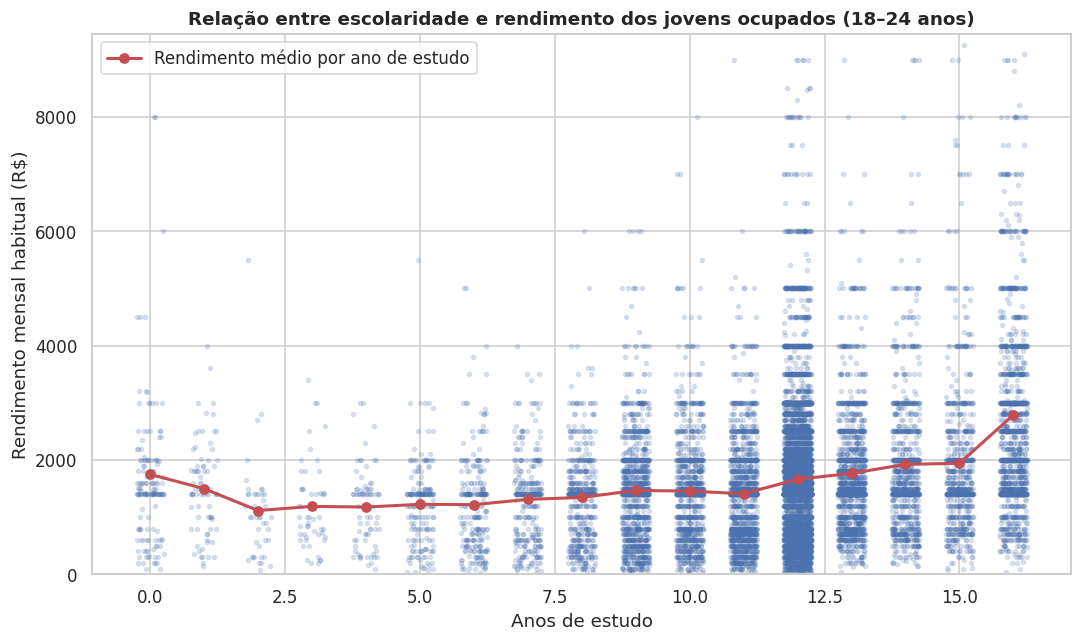

Nota: eixo Y limitado ao P99,5 (R$ 9.000); 106 pontos acima do limite não aparecem no gráfico, mas entram nos cálculos.


,Medida,Valor
0,Covariância (anos × R$),"584,63"
1,Correlação de Pearson (r),"0,1710"
2,IC 95% de r (Fisher),"[0,1587 ; 0,1834]"
3,p-valor de r,"< 0,0001"
4,Correlação de Spearman (ρ),"0,2089"
5,p-valor de ρ,"< 0,0001"


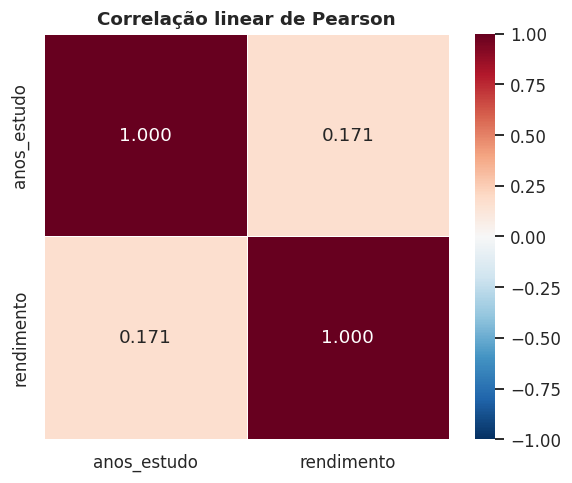

In [19]:
X = base_B["anos_estudo"]
Y = base_B["rendimento"]
n_B = len(base_B)

# (a) gráfico de dispersão
rng = np.random.default_rng(SEED)
jitter = rng.uniform(-0.25, 0.25, n_B)
ylim = Y.quantile(0.995)
n_cortados = int((Y > ylim).sum())

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X + jitter, Y, s=7, alpha=0.18, color="#4C72B0")
medias = base_B.groupby("anos_estudo")["rendimento"].mean()
ax.plot(medias.index, medias.values, color="#C44E52", marker="o", lw=2, label="Rendimento médio por ano de estudo")
ax.set_ylim(0, ylim * 1.05)
ax.set_title("Relação entre escolaridade e rendimento dos jovens ocupados (18–24 anos)")
ax.set_xlabel("Anos de estudo"); ax.set_ylabel("Rendimento mensal habitual (R$)"); ax.legend()
salvar_fig("etapa6_dispersao")
print(f"Nota: eixo Y limitado ao P99,5 ({brl(ylim, 0)}); {n_cortados} pontos acima do limite não aparecem no gráfico, mas entram nos cálculos.")

# (b) covariância e correlação
cov_xy = np.cov(X, Y, ddof=1)[0, 1]
r_p, p_r = stats.pearsonr(X, Y)
rho_s, p_rho = stats.spearmanr(X, Y)
z_f = np.arctanh(r_p); ep = 1 / np.sqrt(n_B - 3)
ic_r = (np.tanh(z_f - 1.96 * ep), np.tanh(z_f + 1.96 * ep))

tab_biv = pd.DataFrame({
    "Medida": ["Covariância (anos × R$)", "Correlação de Pearson (r)", "IC 95% de r (Fisher)", "p-valor de r", "Correlação de Spearman (ρ)", "p-valor de ρ"],
    "Valor": [num(cov_xy, 2), num(r_p, 4), f"[{num(ic_r[0], 4)} ; {num(ic_r[1], 4)}]", pnum(p_r), num(rho_s, 4), pnum(p_rho)],
})
display(tab_biv)
salvar_tab(tab_biv, "etapa6_cov_correlacao", index=False)

# (c) gráfico de correlação
matriz = base_B[["anos_estudo", "rendimento"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax)
ax.set_title("Correlação linear de Pearson")
salvar_fig("etapa6_heatmap_correlacao")

Equação da regressão linear simples:
  rendimento = 499,43 + 102,5444·anos_estudo


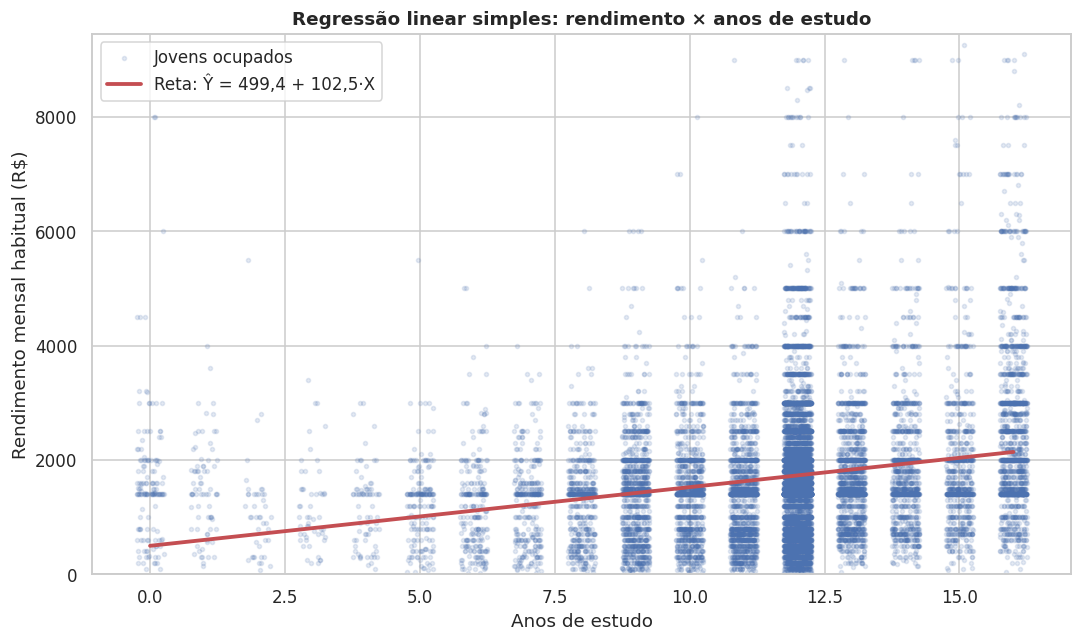

,Medida,Valor
0,R²,"0,0293"
1,R² ajustado,"0,0292"
2,Estatística F,"714,63"
3,p-valor do teste F,"< 0,0001"
4,gl (modelo; resíduo),1; 23714
5,β1 (R$ por ano de estudo),"102,54"
6,IC 95% de β1,"[95,03 ; 110,06]"
7,Estatística t de β1,"26,73"
8,p-valor bilateral de β1,"< 0,0001"
9,p-valor unilateral (H1: β1 > 0),"< 0,0001"


                            OLS Regression Results                            
Dep. Variable:             rendimento   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     714.6
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          3.91e-155
Time:                        23:04:32   Log-Likelihood:            -2.0563e+05
No. Observations:               23716   AIC:                         4.113e+05
Df Residuals:                   23714   BIC:                         4.113e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     499.4301     45.968     10.865      

In [20]:
# (d) regressão linear simples
mod_s = smf.ols("rendimento ~ anos_estudo", data=base_B).fit()
b0, b1 = mod_s.params["Intercept"], mod_s.params["anos_estudo"]
eq_simples = equacao(mod_s.params, y="rendimento")
print("Equação da regressão linear simples:\n ", eq_simples)

# verificação cruzada com scikit-learn (mesmos coeficientes)
lr = LinearRegression().fit(base_B[["anos_estudo"]], base_B["rendimento"])
assert np.isclose(lr.intercept_, b0) and np.isclose(lr.coef_[0], b1), "Coeficientes divergentes entre statsmodels e sklearn"

xs = np.linspace(0, 16, 100)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X + jitter, Y, s=7, alpha=0.15, color="#4C72B0", label="Jovens ocupados")
ax.plot(xs, b0 + b1 * xs, color="#C44E52", lw=2.5, label=f"Reta: Ŷ = {num(b0, 1)} + {num(b1, 1)}·X")
ax.set_ylim(0, ylim * 1.05)
ax.set_title("Regressão linear simples: rendimento × anos de estudo")
ax.set_xlabel("Anos de estudo"); ax.set_ylabel("Rendimento mensal habitual (R$)"); ax.legend()
salvar_fig("etapa6_reta_regressao")

# (e) adequação do modelo
ic_b1 = mod_s.conf_int().loc["anos_estudo"]
p_b1_uni = p_unilateral(mod_s.pvalues["anos_estudo"], b1, ">")
rmse = np.sqrt(mod_s.mse_resid)
adeq = pd.DataFrame({
    "Medida": ["R²", "R² ajustado", "Estatística F", "p-valor do teste F", "gl (modelo; resíduo)", "β1 (R$ por ano de estudo)", "IC 95% de β1",
               "Estatística t de β1", "p-valor bilateral de β1", "p-valor unilateral (H1: β1 > 0)", "Erro-padrão residual (R$)"],
    "Valor": [num(mod_s.rsquared, 4), num(mod_s.rsquared_adj, 4), num(float(mod_s.fvalue), 2), pnum(float(mod_s.f_pvalue)),
              f"{int(mod_s.df_model)}; {int(mod_s.df_resid)}", num(b1, 2), f"[{num(ic_b1[0], 2)} ; {num(ic_b1[1], 2)}]",
              num(mod_s.tvalues["anos_estudo"], 2), pnum(mod_s.pvalues["anos_estudo"]), pnum(p_b1_uni), num(rmse, 2)],
})
display(adeq)
salvar_tab(adeq, "etapa6_adequacao_modelo", index=False)
print(mod_s.summary())

In [21]:
# (f) previsão
novo = pd.DataFrame({"anos_estudo": [4, 8, 11, 12, 16]})
pred = mod_s.get_prediction(novo).summary_frame(alpha=0.05)
tab_pred = pd.concat([novo, pred[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]]], axis=1)
tab_pred.columns = ["anos_estudo", "previsão (R$)", "IC 95% média — inf.", "IC 95% média — sup.", "IC 95% individual — inf.", "IC 95% individual — sup."]
display(tab_pred.round(2))
salvar_tab(tab_pred.round(2), "etapa6_previsoes", index=False)
p12 = tab_pred[tab_pred["anos_estudo"] == 12].iloc[0]

# robustez: log, sem o 1% mais alto, ponderado
base_trim = base_B[base_B["rendimento"] <= base_B["rendimento"].quantile(0.99)]
mod_log = smf.ols("log_rendimento ~ anos_estudo", data=base_B).fit()
mod_trim = smf.ols("rendimento ~ anos_estudo", data=base_trim).fit()
mod_wls = smf.wls("rendimento ~ anos_estudo", data=base_B, weights=base_B["peso"]).fit()
rob_s = pd.DataFrame([
    ["Principal (rendimento em R$)", mod_s],
    ["Logaritmo do rendimento", mod_log],
    ["Sem o 1% de maiores rendimentos", mod_trim],
    ["Ponderado pelo peso amostral (WLS)", mod_wls],
], columns=["Modelo", "obj"])
rob_s["n"] = [int(m.nobs) for m in rob_s["obj"]]
rob_s["β1"] = [m.params["anos_estudo"] for m in rob_s["obj"]]
rob_s["p-valor (bilateral)"] = [m.pvalues["anos_estudo"] for m in rob_s["obj"]]
rob_s["R²"] = [m.rsquared for m in rob_s["obj"]]
rob_s = rob_s.drop(columns="obj")
display(rob_s.round(4))
salvar_tab(rob_s.round(6), "etapa6_robustez", index=False)

efeito_log = (np.exp(mod_log.params["anos_estudo"]) - 1) * 100

linhas = [
    f"**Dispersão:** a nuvem de pontos é {'ascendente' if medias.iloc[-1] > medias.iloc[0] else 'sem tendência ascendente clara'}, mas muito dispersa em cada nível de escolaridade (a variabilidade do rendimento é grande mesmo entre jovens com os mesmos anos de estudo); a média por ano de estudo {'sobe' if medias.iloc[-1] > medias.iloc[0] else 'não sobe'} ao longo do eixo.",
    f"**Covariância = {num(cov_xy, 1)}** (sinal {'positivo' if cov_xy > 0 else 'negativo'}: as variáveis tendem a variar {'no mesmo sentido' if cov_xy > 0 else 'em sentidos opostos'}). Sua magnitude depende das unidades e não mede a intensidade.",
    f"**Correlação de Pearson r = {num(r_p, 3)}** (IC 95%: {num(ic_r[0], 3)} a {num(ic_r[1], 3)}): associação linear {sentido(r_p)} e **{forca_corr(r_p)}**. Spearman ρ = {num(rho_s, 3)}, {'consistente com' if np.sign(rho_s) == np.sign(r_p) else 'divergente de'} Pearson.",
    f"**Equação:** `{eq_simples}`. Cada ano adicional de estudo está associado, em média, a **{brl(b1)}** a mais de rendimento mensal (IC 95%: {brl(ic_b1[0])} a {brl(ic_b1[1])}); o intercepto ({brl(b0)}) é o valor extrapolado para 0 ano de estudo.",
    f"**Adequação:** R² = {num(mod_s.rsquared, 3)}, isto é, a escolaridade sozinha explica {pct(mod_s.rsquared)} da variação do rendimento. O teste F (F = {num(float(mod_s.fvalue), 1)}; p {pval(float(mod_s.f_pvalue))}) {'rejeita' if mod_s.f_pvalue < 0.05 else 'não rejeita'} a hipótese de que o modelo não explica nada; o teste unilateral de $\\beta_1 > 0$ tem p {pval(p_b1_uni)}.",
    f"**Leitura conjunta:** {'o efeito é estatisticamente significativo, mas o R² indica que a escolaridade é apenas um dos fatores que influenciam o rendimento' if (mod_s.f_pvalue < 0.05 and mod_s.rsquared < 0.3) else 'o modelo apresenta ajuste relevante' if mod_s.f_pvalue < 0.05 else 'não há evidência de relação linear significativa'}. Com amostra grande, até efeitos pequenos ficam significativos; por isso importa olhar o tamanho do efeito (R$ por ano) e o R².",
    f"**Previsão:** para 12 anos de estudo, o rendimento médio previsto é **{brl(p12['previsão (R$)'])}** (IC 95% da média: {brl(p12['IC 95% média — inf.'])} a {brl(p12['IC 95% média — sup.'])}). Para um jovem específico o intervalo de predição é bem mais largo ({brl(p12['IC 95% individual — inf.'])} a {brl(p12['IC 95% individual — sup.'])}).",
    f"**Robustez:** β1 permanece {'positivo e significativo' if (rob_s['β1'] > 0).all() and (rob_s['p-valor (bilateral)'] < 0.05).all() else 'com variações de sinal ou significância'} nas quatro especificações; no modelo em logaritmo, cada ano de estudo se associa a um rendimento cerca de {num(efeito_log, 1)}% maior.",
]
relatar("Relatório", linhas)
RES.update(r_pearson=r_p, cov_xy=cov_xy, b0=b0, b1=b1, r2_simples=mod_s.rsquared, f_simples=float(mod_s.fvalue), pF_simples=float(mod_s.f_pvalue),
           p_b1_uni=p_b1_uni, pred12=p12["previsão (R$)"], eq_simples=eq_simples, efeito_log=efeito_log)

,anos_estudo,previsão (R$),IC 95% média — inf.,IC 95% média — sup.,IC 95% individual — inf.,IC 95% individual — sup.
0,4,909.61,848.68,970.53,-1855.69,3674.90
1,8,1319.79,1286.40,1353.17,-1445.04,4084.61
2,11,1627.42,1608.62,1646.22,-1137.27,4392.11
3,12,1729.96,1711.91,1748.02,-1034.72,4494.65
4,16,2140.14,2103.45,2176.84,-624.73,4905.01


,Modelo,n,β1,p-valor (bilateral),R²
0,Principal (rendimento em R$),23716,102.5444,0.0,0.0293
1,Logaritmo do rendimento,23716,0.0610,0.0,0.0450
2,Sem o 1% de maiores rendimentos,23491,75.8106,0.0,0.0405
3,Ponderado pelo peso amostral (WLS),23716,113.8652,0.0,0.0306


### Relatório

- **Dispersão:** a nuvem de pontos é ascendente, mas muito dispersa em cada nível de escolaridade (a variabilidade do rendimento é grande mesmo entre jovens com os mesmos anos de estudo); a média por ano de estudo sobe ao longo do eixo.
- **Covariância = 584,6** (sinal positivo: as variáveis tendem a variar no mesmo sentido). Sua magnitude depende das unidades e não mede a intensidade.
- **Correlação de Pearson r = 0,171** (IC 95%: 0,159 a 0,183): associação linear positiva e **fraca**. Spearman ρ = 0,209, consistente com Pearson.
- **Equação:** `rendimento = 499,43 + 102,5444·anos_estudo`. Cada ano adicional de estudo está associado, em média, a **R$ 102,54** a mais de rendimento mensal (IC 95%: R$ 95,03 a R$ 110,06); o intercepto (R$ 499,43) é o valor extrapolado para 0 ano de estudo.
- **Adequação:** R² = 0,029, isto é, a escolaridade sozinha explica 2,9% da variação do rendimento. O teste F (F = 714,6; p < 0,0001) rejeita a hipótese de que o modelo não explica nada; o teste unilateral de $\beta_1 > 0$ tem p < 0,0001.
- **Leitura conjunta:** o efeito é estatisticamente significativo, mas o R² indica que a escolaridade é apenas um dos fatores que influenciam o rendimento. Com amostra grande, até efeitos pequenos ficam significativos; por isso importa olhar o tamanho do efeito (R$ por ano) e o R².
- **Previsão:** para 12 anos de estudo, o rendimento médio previsto é **R$ 1.729,96** (IC 95% da média: R$ 1.711,91 a R$ 1.748,02). Para um jovem específico o intervalo de predição é bem mais largo (R$ -1.034,72 a R$ 4.494,65).
- **Robustez:** β1 permanece positivo e significativo nas quatro especificações; no modelo em logaritmo, cada ano de estudo se associa a um rendimento cerca de 6,3% maior.

---
# Etapa 7 — Regressão linear múltipla

Modelar o rendimento em função de **anos de estudo** ($X_1$), **idade** ($X_2$) e **horas semanais habituais** ($X_3$), verificando a adequação do modelo e fazendo previsão com mais de uma variável explicativa.

1. **As três variáveis quantitativas explicativas seguem a proposta.** Idade e horas trabalhadas são controles naturais: entre jovens de 18 a 24 anos, mais idade pode significar mais experiência e jornadas maiores significam, em geral, mais rendimento. Sem controlá-las, o coeficiente de escolaridade poderia estar capturando parte desses efeitos.
2. **Matriz de correlação antes do modelo**, para checar a presença de variáveis explicativas muito correlacionadas entre si (multicolinearidade) e quais têm relação mais forte com o rendimento.
3. **Adequação além de R² e F** (que o enunciado pede):
   - **R² ajustado**, que penaliza o acréscimo de variáveis;
   - **VIF** (fator de inflação da variância) para multicolinearidade: valores acima de 5 (ou 10) indicam problema;
   - **Resíduos × valores ajustados, histograma e Q-Q plot dos resíduos**, e **teste de Breusch-Pagan** para variância não constante (heterocedasticidade);
   - **Erros-padrão robustos (HC3)**: se há heterocedasticidade, os erros-padrão usuais são pouco confiáveis; os robustos mostram se as conclusões de significância se mantêm.
4. **Coeficientes padronizados** (efeito de 1 desvio padrão de cada variável), para comparar a importância relativa de variáveis medidas em unidades distintas (anos, horas).
5. **Interpretação *ceteris paribus*:** cada coeficiente é o efeito de uma variável mantendo as outras constantes.
6. **Hipóteses.** Global: $H_0: \beta_1=\beta_2=\beta_3=0$ (teste F). Escolaridade: $H_0: \beta_1 = 0$ vs $H_1: \beta_1 > 0$, com p-valor unilateral.
7. **Previsão com 3 variáveis:** jovem de 22 anos, 12 anos de estudo, 40 h/semana (cenário da proposta), mais cenários comparativos. Os valores ficam dentro do intervalo observado das variáveis (idade 18–24), evitando extrapolação.
8. **Robustez** idêntica à da Etapa 6 (log, sem o 1% mais alto, ponderado), com foco na estabilidade do coeficiente de escolaridade.

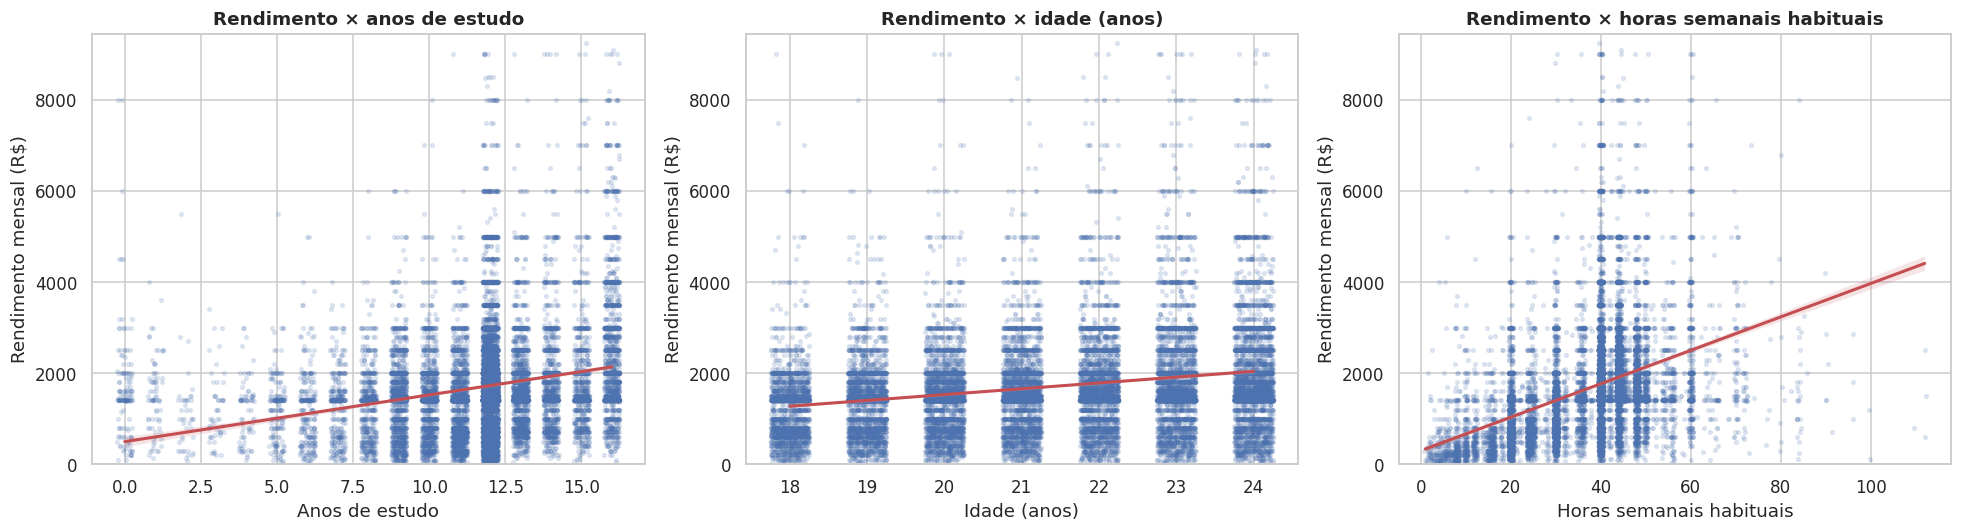

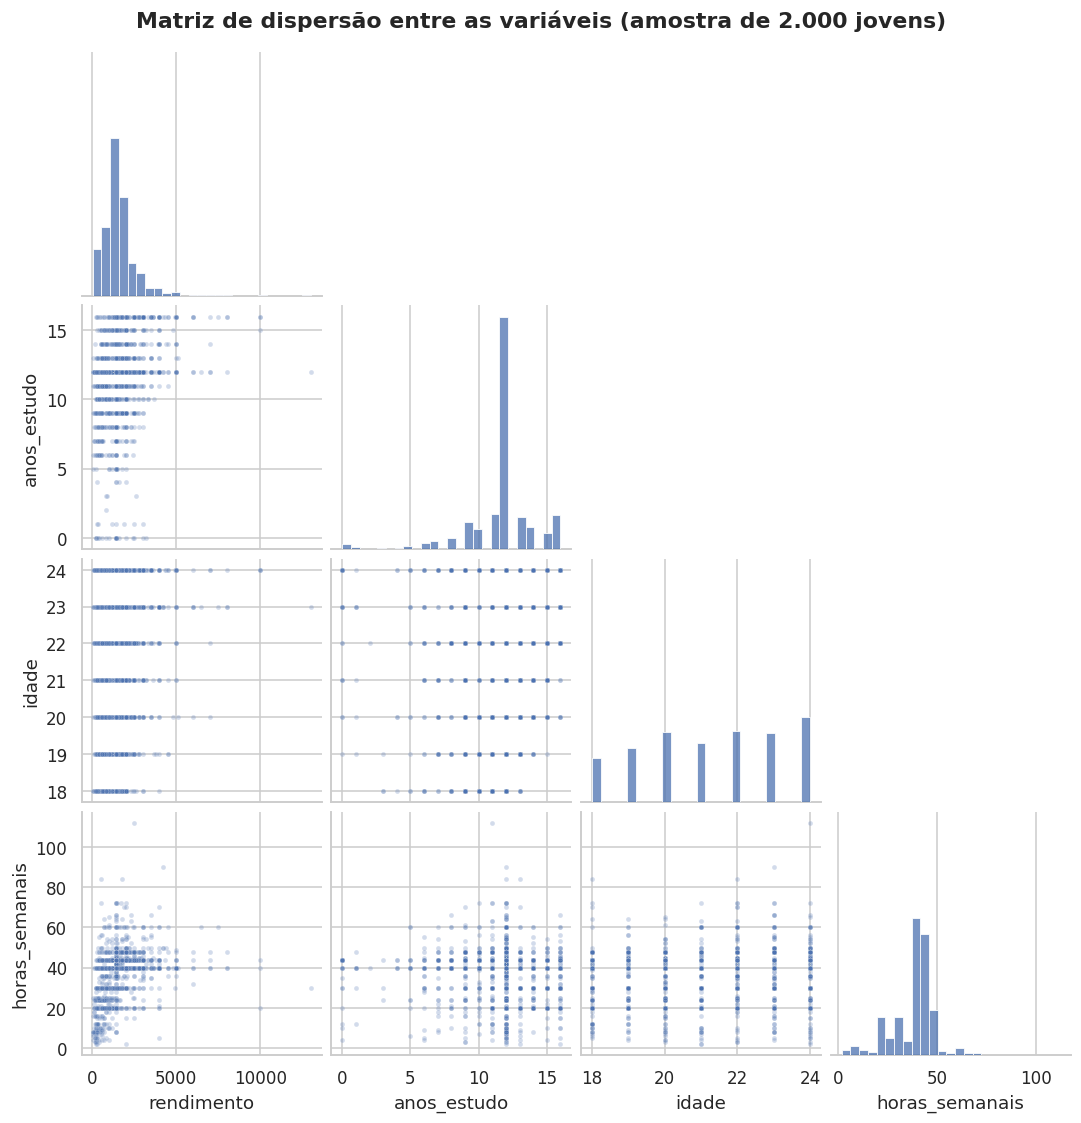

Matriz de covariância:


,rendimento,anos_estudo,idade,horas_semanais
rendimento,2049311.21,584.63,481.97,4435.32
anos_estudo,584.63,5.70,0.71,-1.21
idade,481.97,0.71,3.78,2.01
horas_semanais,4435.32,-1.21,2.01,120.93


Matriz de correlação de Pearson:


,rendimento,anos_estudo,idade,horas_semanais
rendimento,1.0000,0.1710,0.1732,0.2817
anos_estudo,0.1710,1.0000,0.1540,-0.0459
idade,0.1732,0.1540,1.0000,0.0939
horas_semanais,0.2817,-0.0459,0.0939,1.0000


Matriz de correlação de Spearman (verificação):


,rendimento,anos_estudo,idade,horas_semanais
rendimento,1.0000,0.2089,0.2134,0.3968
anos_estudo,0.2089,1.0000,0.2033,-0.0816
idade,0.2134,0.2033,1.0000,0.0782
horas_semanais,0.3968,-0.0816,0.0782,1.0000


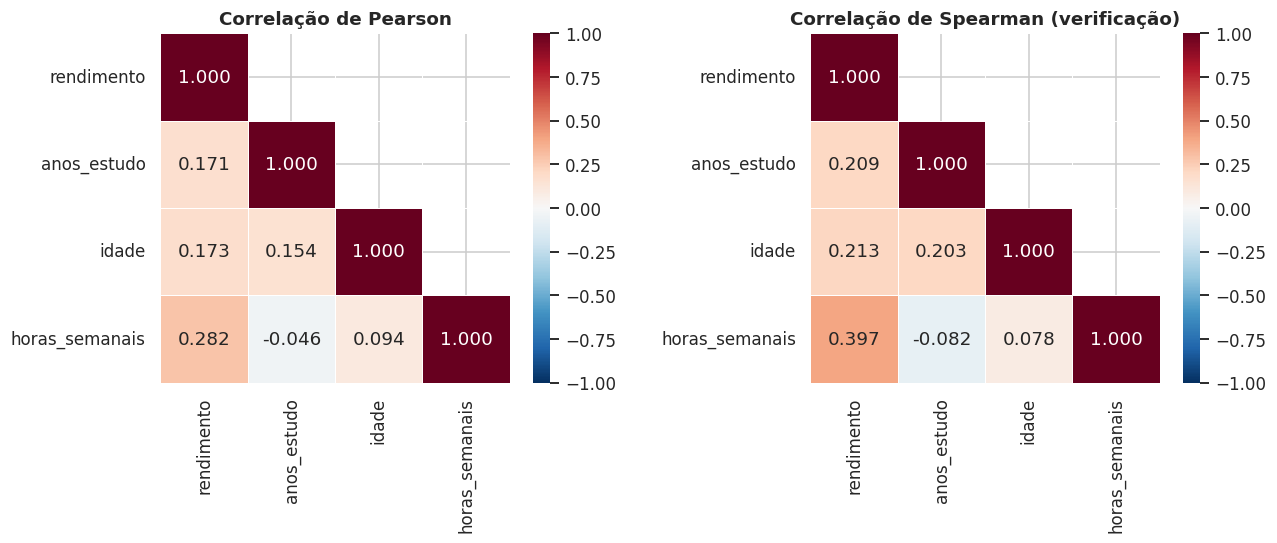

In [22]:
vars_m = ["rendimento", "anos_estudo", "idade", "horas_semanais"]

# (a) gráficos de dispersão
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, v, rot in zip(axes, ["anos_estudo", "idade", "horas_semanais"], ["Anos de estudo", "Idade (anos)", "Horas semanais habituais"]):
    sns.regplot(data=base_B, x=v, y="rendimento", x_jitter=0.25 if v != "horas_semanais" else 0.5,
                scatter_kws=dict(s=6, alpha=0.15, color="#4C72B0"), line_kws=dict(color="#C44E52", lw=2), ax=ax)
    ax.set_ylim(0, ylim * 1.05)
    ax.set_title(f"Rendimento × {rot.lower()}"); ax.set_xlabel(rot); ax.set_ylabel("Rendimento mensal (R$)")
salvar_fig("etapa7_dispersoes")

amostra_pair = base_B[vars_m].sample(min(2000, len(base_B)), random_state=SEED)
g = sns.pairplot(amostra_pair, corner=True, plot_kws=dict(alpha=0.25, s=10), diag_kws=dict(bins=25))
g.figure.suptitle("Matriz de dispersão entre as variáveis (amostra de 2.000 jovens)", y=1.02, fontweight="bold")
plt.savefig(f"{DIR_FIG}/etapa7_pairplot.png", dpi=150, bbox_inches="tight"); plt.show()

# (b) matrizes de covariância e correlação
cov_m = base_B[vars_m].cov()
corr_m = base_B[vars_m].corr(method="pearson")
corr_sp = base_B[vars_m].corr(method="spearman")
print("Matriz de covariância:"); display(cov_m.round(2))
print("Matriz de correlação de Pearson:"); display(corr_m.round(4))
print("Matriz de correlação de Spearman (verificação):"); display(corr_sp.round(4))
salvar_tab(cov_m.round(4), "etapa7_matriz_covariancia")
salvar_tab(corr_m.round(4), "etapa7_matriz_correlacao")

# (c) gráfico de correlação
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
mask = np.triu(np.ones_like(corr_m, dtype=bool), k=1)
sns.heatmap(corr_m, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=.5, mask=mask, ax=axes[0])
axes[0].set_title("Correlação de Pearson")
sns.heatmap(corr_sp, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=.5, mask=mask, ax=axes[1])
axes[1].set_title("Correlação de Spearman (verificação)")
salvar_fig("etapa7_heatmap_correlacao")

Equação da regressão linear múltipla:
  rendimento = -2.754,67 + 98,9489·anos_estudo + 89,6684·idade + 36,1744·horas_semanais


,coeficiente,erro-padrão,t,p-valor (bilateral),IC 95% inf.,IC 95% sup.,coef. padronizado
Intercept,-2754.6705,102.5102,-26.8721,0.0,-2955.5972,-2553.7439,NaN
anos_estudo,98.9489,3.6874,26.8340,0.0,91.7213,106.1766,0.1650
idade,89.6684,4.5459,19.7251,0.0,80.7581,98.5787,0.1217
horas_semanais,36.1744,0.7946,45.5252,0.0,34.6170,37.7319,0.2779


,Medida,Valor
0,R²,"0,1276"
1,R² ajustado,"0,1275"
2,Estatística F,"1.156,16"
3,p-valor do teste F,"< 0,0001"
4,gl (modelo; resíduo),3; 23712
5,p-valor unilateral de β1 (escolaridade > 0),"< 0,0001"
6,Erro-padrão residual (R$),"1.337,17"
7,AIC,"408.737,4"


                            OLS Regression Results                            
Dep. Variable:             rendimento   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.127
Method:                 Least Squares   F-statistic:                     1156.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:04:50   Log-Likelihood:            -2.0436e+05
No. Observations:               23716   AIC:                         4.087e+05
Df Residuals:                   23712   BIC:                         4.088e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept      -2754.6705    102.510    -26.

,variável,VIF
0,anos_estudo,1.028
1,idade,1.035
2,horas_semanais,1.013


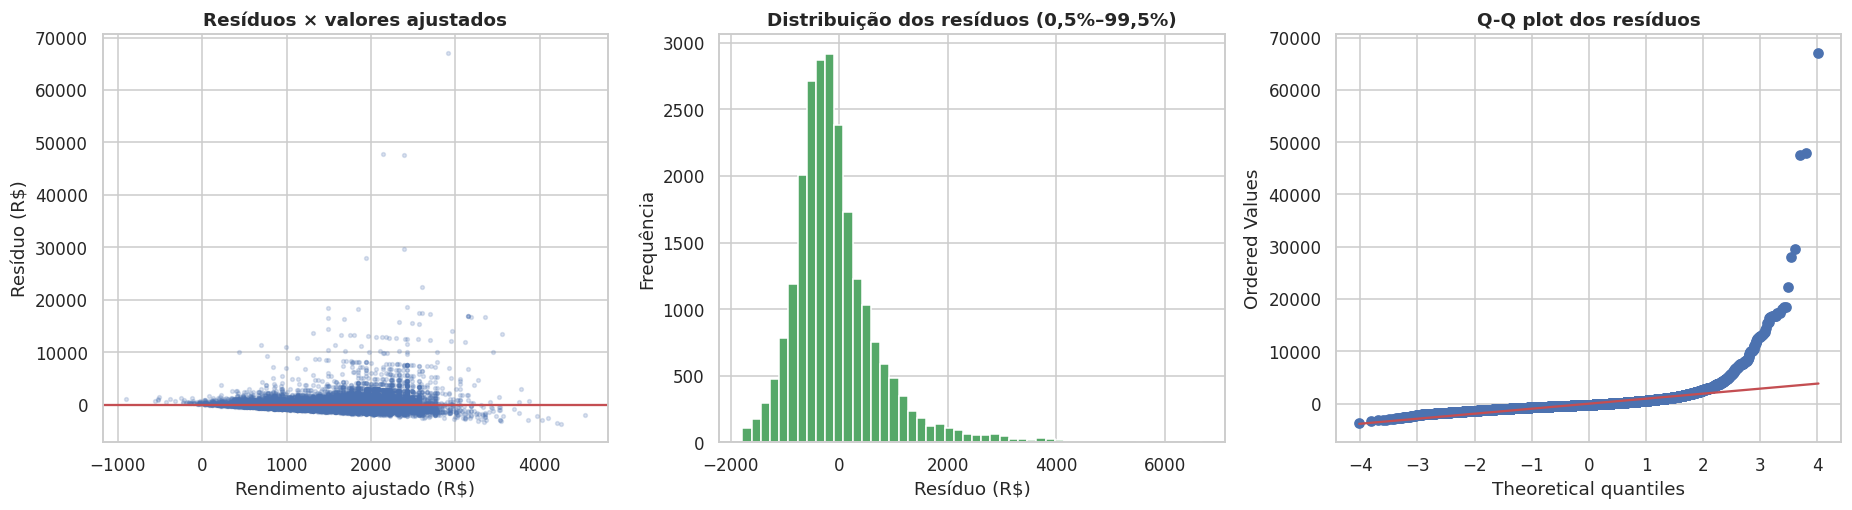

Breusch-Pagan: LM = 47,90, p < 0,0001 | assimetria dos resíduos = 13,66


,coef.,p-valor (usual),EP (usual),EP (HC3),p-valor (HC3)
Intercept,-2754.6705,0.0,102.5102,121.8158,0.0
anos_estudo,98.9489,0.0,3.6874,4.5664,0.0
idade,89.6684,0.0,4.5459,4.2834,0.0
horas_semanais,36.1744,0.0,0.7946,1.0192,0.0


In [23]:
# (d) regressão linear múltipla
formula_m = "rendimento ~ anos_estudo + idade + horas_semanais"
mod_m = smf.ols(formula_m, data=base_B).fit()
eq_multipla = equacao(mod_m.params, y="rendimento")
print("Equação da regressão linear múltipla:\n ", eq_multipla)

ic_m = mod_m.conf_int()
coef = pd.DataFrame({"coeficiente": mod_m.params, "erro-padrão": mod_m.bse, "t": mod_m.tvalues, "p-valor (bilateral)": mod_m.pvalues,
                     "IC 95% inf.": ic_m[0], "IC 95% sup.": ic_m[1]})
sd_y = base_B["rendimento"].std()
coef["coef. padronizado"] = [np.nan] + [mod_m.params[v] * base_B[v].std() / sd_y for v in ["anos_estudo", "idade", "horas_semanais"]]
display(coef.round(4))
salvar_tab(coef.round(6), "etapa7_coeficientes")

b_edu_m = mod_m.params["anos_estudo"]
p_edu_uni = p_unilateral(mod_m.pvalues["anos_estudo"], b_edu_m, ">")

# (e) adequação
adeq_m = pd.DataFrame({
    "Medida": ["R²", "R² ajustado", "Estatística F", "p-valor do teste F", "gl (modelo; resíduo)", "p-valor unilateral de β1 (escolaridade > 0)", "Erro-padrão residual (R$)", "AIC"],
    "Valor": [num(mod_m.rsquared, 4), num(mod_m.rsquared_adj, 4), num(float(mod_m.fvalue), 2), pnum(float(mod_m.f_pvalue)),
              f"{int(mod_m.df_model)}; {int(mod_m.df_resid)}", pnum(p_edu_uni), num(np.sqrt(mod_m.mse_resid), 2), num(mod_m.aic, 1)],
})
display(adeq_m)
salvar_tab(adeq_m, "etapa7_adequacao", index=False)
print(mod_m.summary())

# multicolinearidade
Xm = mod_m.model.exog; nomes = mod_m.model.exog_names
vif = pd.DataFrame({"variável": nomes[1:], "VIF": [variance_inflation_factor(Xm, i) for i in range(1, Xm.shape[1])]})
display(vif.round(3))
salvar_tab(vif.round(4), "etapa7_vif", index=False)

# resíduos
resid, ajust = mod_m.resid, mod_m.fittedvalues
bp_lm, bp_p, _, _ = het_breuschpagan(resid, mod_m.model.exog)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(ajust, resid, s=6, alpha=0.2, color="#4C72B0"); axes[0].axhline(0, color="#C44E52")
axes[0].set_title("Resíduos × valores ajustados"); axes[0].set_xlabel("Rendimento ajustado (R$)"); axes[0].set_ylabel("Resíduo (R$)")
axes[1].hist(resid[resid.between(resid.quantile(.005), resid.quantile(.995))], bins=50, color="#55A868", edgecolor="white")
axes[1].set_title("Distribuição dos resíduos (0,5%–99,5%)"); axes[1].set_xlabel("Resíduo (R$)"); axes[1].set_ylabel("Frequência")
stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot dos resíduos")
salvar_fig("etapa7_residuos")
print(f"Breusch-Pagan: LM = {num(bp_lm, 2)}, p {pval(bp_p)} | assimetria dos resíduos = {num(stats.skew(resid), 2)}")

# erros-padrão robustos (HC3)
mod_hc3 = smf.ols(formula_m, data=base_B).fit(cov_type="HC3")
comp_hc3 = pd.DataFrame({"coef.": mod_m.params, "p-valor (usual)": mod_m.pvalues, "EP (usual)": mod_m.bse, "EP (HC3)": mod_hc3.bse, "p-valor (HC3)": mod_hc3.pvalues})
display(comp_hc3.round(4))
salvar_tab(comp_hc3.round(6), "etapa7_erros_robustos")

In [24]:
# (f) previsão com 3 variáveis explicativas
cenarios = pd.DataFrame({
    "cenário": ["Cenário da proposta", "Menor escolaridade, mesma idade e jornada", "Maior escolaridade, mesma idade e jornada", "Jovem de 18 anos, 12 anos de estudo, 40 h"],
    "idade": [22, 22, 22, 18], "anos_estudo": [12, 8, 16, 12], "horas_semanais": [40, 40, 40, 40]})
pm = mod_m.get_prediction(cenarios[["idade", "anos_estudo", "horas_semanais"]]).summary_frame(alpha=0.05)
tab_pm = pd.concat([cenarios, pm[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]]], axis=1)
tab_pm = tab_pm.rename(columns={"mean": "previsão (R$)", "mean_ci_lower": "IC 95% média — inf.", "mean_ci_upper": "IC 95% média — sup.",
                                "obs_ci_lower": "IC 95% individual — inf.", "obs_ci_upper": "IC 95% individual — sup."})
display(tab_pm.round(2))
salvar_tab(tab_pm.round(2), "etapa7_previsoes", index=False)
pm0 = tab_pm.iloc[0]

# robustez
base_trim = base_B[base_B["rendimento"] <= base_B["rendimento"].quantile(0.99)]
modelos_rob = {
    "Principal (rendimento em R$)": mod_m,
    "Logaritmo do rendimento": smf.ols("log_rendimento ~ anos_estudo + idade + horas_semanais", data=base_B).fit(),
    "Sem o 1% de maiores rendimentos": smf.ols(formula_m, data=base_trim).fit(),
    "Ponderado pelo peso amostral (WLS)": smf.wls(formula_m, data=base_B, weights=base_B["peso"]).fit(),
}
rob_m = pd.DataFrame({
    "Modelo": list(modelos_rob),
    "β escolaridade": [m.params["anos_estudo"] for m in modelos_rob.values()],
    "p-valor (bilateral)": [m.pvalues["anos_estudo"] for m in modelos_rob.values()],
    "β idade": [m.params["idade"] for m in modelos_rob.values()],
    "β horas": [m.params["horas_semanais"] for m in modelos_rob.values()],
    "R²": [m.rsquared for m in modelos_rob.values()],
    "R² ajustado": [m.rsquared_adj for m in modelos_rob.values()],
})
display(rob_m.round(4))
salvar_tab(rob_m.round(6), "etapa7_robustez", index=False)

# ---------- achados ----------
maior_corr = corr_m.loc[["anos_estudo", "idade", "horas_semanais"], "rendimento"].abs().idxmax()
corr_entre = corr_m.loc[["anos_estudo", "idade", "horas_semanais"], ["anos_estudo", "idade", "horas_semanais"]].abs().where(~np.eye(3, dtype=bool)).max().max()
padr = coef["coef. padronizado"].drop("Intercept")
nomes_pt = {"anos_estudo": "anos de estudo", "idade": "idade", "horas_semanais": "horas semanais"}
sig = {v: mod_m.pvalues[v] < 0.05 for v in ["anos_estudo", "idade", "horas_semanais"]}
mudou_hc3 = [nomes_pt[v] for v in sig if (comp_hc3.loc[v, "p-valor (HC3)"] < 0.05) != sig[v]]
efeito_log_m = (np.exp(modelos_rob["Logaritmo do rendimento"].params["anos_estudo"]) - 1) * 100

linhas = [
    f"**Correlações com o rendimento:** anos de estudo r = {num(corr_m.loc['anos_estudo', 'rendimento'], 3)}, idade r = {num(corr_m.loc['idade', 'rendimento'], 3)} e horas semanais r = {num(corr_m.loc['horas_semanais', 'rendimento'], 3)}. A associação linear mais forte com o rendimento é a de **{nomes_pt[maior_corr]}**.",
    f"**Entre as explicativas**, a maior correlação absoluta é {num(corr_entre, 3)}, e o maior VIF é {num(vif['VIF'].max(), 2)} → {'sem sinal de multicolinearidade preocupante' if vif['VIF'].max() < 5 else 'há multicolinearidade relevante, e os coeficientes individuais devem ser lidos com cautela'}.",
    f"**Equação:** `{eq_multipla}`.",
    f"**Interpretação dos coeficientes (ceteris paribus):** cada ano de estudo adicional se associa a {brl(mod_m.params['anos_estudo'])} a mais de rendimento ({'significativo' if sig['anos_estudo'] else 'não significativo'}); cada ano de idade, a {brl(mod_m.params['idade'])} ({'significativo' if sig['idade'] else 'não significativo'}); cada hora semanal a mais, a {brl(mod_m.params['horas_semanais'])} ({'significativo' if sig['horas_semanais'] else 'não significativo'}). Pelos coeficientes padronizados, a variável de maior peso relativo é **{nomes_pt[padr.abs().idxmax()]}**.",
    f"**Comparação com o modelo simples:** o efeito de um ano de estudo foi de {brl(RES['b1'])} (simples) para {brl(b_edu_m)} (múltiplo). {'A redução indica que parte da associação inicial era compartilhada com idade e horas trabalhadas.' if b_edu_m < RES['b1'] else 'O efeito não diminuiu ao controlar idade e horas.'}",
    f"**Adequação global:** R² = {num(mod_m.rsquared, 3)} (R² ajustado = {num(mod_m.rsquared_adj, 3)}); teste F = {num(float(mod_m.fvalue), 1)} (p {pval(float(mod_m.f_pvalue))}) → {'rejeita-se' if mod_m.f_pvalue < 0.05 else 'não se rejeita'} $H_0: \\beta_1=\\beta_2=\\beta_3=0$. Teste unilateral de escolaridade ($\\beta_1 > 0$): p {pval(p_edu_uni)}. O modelo explica {pct(mod_m.rsquared)} da variação do rendimento — {'a maior parte da variação continua sem explicação' if mod_m.rsquared < 0.5 else 'um ajuste razoável'}.",
    f"**Diagnóstico:** Breusch-Pagan p {pval(bp_p)} → {'há evidência de heterocedasticidade' if bp_p < 0.05 else 'sem evidência de heterocedasticidade'}; assimetria dos resíduos = {num(stats.skew(resid), 2)} ({'resíduos fortemente assimétricos, o que viola a hipótese de normalidade dos erros' if abs(stats.skew(resid)) > 1 else 'resíduos aproximadamente simétricos'}). Com erros-padrão robustos (HC3), {'as conclusões de significância não mudam' if not mudou_hc3 else 'a significância muda para: ' + ', '.join(mudou_hc3)}.",
    f"**Previsão (22 anos, 12 anos de estudo, 40 h/semana):** rendimento médio previsto de **{brl(pm0['previsão (R$)'])}** (IC 95% da média: {brl(pm0['IC 95% média — inf.'])} a {brl(pm0['IC 95% média — sup.'])}; intervalo de predição individual: {brl(pm0['IC 95% individual — inf.'])} a {brl(pm0['IC 95% individual — sup.'])}). O limite inferior do intervalo individual {'é negativo, o que não é plausível e reflete a limitação do modelo linear para uma variável assimétrica e positiva' if pm0['IC 95% individual — inf.'] < 0 else 'é positivo'}.",
    f"**Robustez:** o coeficiente de escolaridade é {'positivo e significativo em todas as especificações' if (rob_m['β escolaridade'] > 0).all() and (rob_m['p-valor (bilateral)'] < 0.05).all() else 'instável entre especificações'}; no modelo em logaritmo, cada ano de estudo se associa a um rendimento cerca de {num(efeito_log_m, 1)}% maior.",
    "**Limitações:** associação não é causalidade; variáveis relevantes foram omitidas (setor, formalidade, ocupação, região, experiência); o modelo linear em reais é uma aproximação para um rendimento assimétrico; as horas trabalhadas podem ser consequência, e não só causa, do rendimento.",
]
relatar("Relatório", linhas)
RES.update(eq_multipla=eq_multipla, r2_multipla=mod_m.rsquared, r2adj_multipla=mod_m.rsquared_adj, f_multipla=float(mod_m.fvalue), pF_multipla=float(mod_m.f_pvalue),
           b_edu_multipla=b_edu_m, p_edu_multipla=p_edu_uni, pred_multipla=pm0["previsão (R$)"], vif_max=vif["VIF"].max(), bp_p=bp_p)

,cenário,idade,anos_estudo,horas_semanais,previsão (R$),IC 95% média — inf.,IC 95% média — sup.,IC 95% individual — inf.,IC 95% individual — sup.
0,Cenário da proposta,22,12,40,1852.40,1834.27,1870.53,-768.60,4473.40
1,"Menor escolaridade, mesma idade e jornada",22,8,40,1456.60,1423.42,1489.79,-1164.55,4077.75
2,"Maior escolaridade, mesma idade e jornada",22,16,40,2248.19,2213.15,2283.24,-372.98,4869.37
3,"Jovem de 18 anos, 12 anos de estudo, 40 h",18,12,40,1493.73,1458.73,1528.72,-1127.45,4114.90


,Modelo,β escolaridade,p-valor (bilateral),β idade,β horas,R²,R² ajustado
0,Principal (rendimento em R$),98.9489,0.0,89.6684,36.1744,0.1276,0.1275
1,Logaritmo do rendimento,0.0626,0.0,0.0398,0.0310,0.3142,0.3141
2,Sem o 1% de maiores rendimentos,74.3080,0.0,70.6552,31.0809,0.2199,0.2198
3,Ponderado pelo peso amostral (WLS),109.0097,0.0,104.6420,35.2276,0.1180,0.1178


### Relatório

- **Correlações com o rendimento:** anos de estudo r = 0,171, idade r = 0,173 e horas semanais r = 0,282. A associação linear mais forte com o rendimento é a de **horas semanais**.
- **Entre as explicativas**, a maior correlação absoluta é 0,154, e o maior VIF é 1,04 → sem sinal de multicolinearidade preocupante.
- **Equação:** `rendimento = -2.754,67 + 98,9489·anos_estudo + 89,6684·idade + 36,1744·horas_semanais`.
- **Interpretação dos coeficientes (ceteris paribus):** cada ano de estudo adicional se associa a R$ 98,95 a mais de rendimento (significativo); cada ano de idade, a R$ 89,67 (significativo); cada hora semanal a mais, a R$ 36,17 (significativo). Pelos coeficientes padronizados, a variável de maior peso relativo é **horas semanais**.
- **Comparação com o modelo simples:** o efeito de um ano de estudo foi de R$ 102,54 (simples) para R$ 98,95 (múltiplo). A redução indica que parte da associação inicial era compartilhada com idade e horas trabalhadas.
- **Adequação global:** R² = 0,128 (R² ajustado = 0,127); teste F = 1.156,2 (p < 0,0001) → rejeita-se $H_0: \beta_1=\beta_2=\beta_3=0$. Teste unilateral de escolaridade ($\beta_1 > 0$): p < 0,0001. O modelo explica 12,8% da variação do rendimento — a maior parte da variação continua sem explicação.
- **Diagnóstico:** Breusch-Pagan p < 0,0001 → há evidência de heterocedasticidade; assimetria dos resíduos = 13,66 (resíduos fortemente assimétricos, o que viola a hipótese de normalidade dos erros). Com erros-padrão robustos (HC3), as conclusões de significância não mudam.
- **Previsão (22 anos, 12 anos de estudo, 40 h/semana):** rendimento médio previsto de **R$ 1.852,40** (IC 95% da média: R$ 1.834,27 a R$ 1.870,53; intervalo de predição individual: R$ -768,60 a R$ 4.473,40). O limite inferior do intervalo individual é negativo, o que não é plausível e reflete a limitação do modelo linear para uma variável assimétrica e positiva.
- **Robustez:** o coeficiente de escolaridade é positivo e significativo em todas as especificações; no modelo em logaritmo, cada ano de estudo se associa a um rendimento cerca de 6,5% maior.
- **Limitações:** associação não é causalidade; variáveis relevantes foram omitidas (setor, formalidade, ocupação, região, experiência); o modelo linear em reais é uma aproximação para um rendimento assimétrico; as horas trabalhadas podem ser consequência, e não só causa, do rendimento.

---
# Etapa 8 — Regressão logística binária

Estimar a probabilidade de um jovem da força de trabalho estar **ocupado** (1) ou **desocupado** (0) a partir de **idade**, **anos de estudo** e **número de moradores no domicílio**; avaliar a classificação com matriz de confusão e acurácia; e classificar cenários.

**Decisões e justificativas.**
1. **População: Base C (ocupados + desocupados).** Quem está fora da força de trabalho não procura emprego e não pode ser classificado como "desocupado" (Etapa 2).
2. **Equação com três variáveis quantitativas** (idade, anos de estudo, moradores), como na proposta. O modelo é estimado com `statsmodels` porque fornece a equação completa, erros-padrão, p-valores e intervalos de confiança.
3. **Divisão treino/teste 80/20, estratificada pela variável-alvo**, com semente fixa. O modelo é ajustado **apenas no treino** e avaliado **apenas no teste**, para que a acurácia reflita desempenho em dados não vistos. A estratificação mantém, no treino e no teste, a mesma proporção de ocupados e desocupados.
4. **Acurácia não é suficiente com classes desbalanceadas.** Se a grande maioria dos jovens na força de trabalho está ocupada, um "modelo" que classifica *todos* como ocupados já teria acurácia alta, sem aprender nada. Por isso o notebook reporta: a **acurácia do modelo ingênuo** (sempre a classe majoritária), **precisão, recall (sensibilidade), especificidade, F1** e **AUC-ROC** (independe do limiar).
5. **Limiar de 0,5 primeiro** (como pede a proposta); em seguida, um **limiar alternativo escolhido no conjunto de treino** (critério de Youden: maximiza sensibilidade + especificidade − 1). O limiar é escolhido no treino e aplicado ao teste, para não "vazar" informação do teste. A comparação mostra o custo e o benefício de cada limiar.
6. **Hipótese sobre escolaridade:** $H_0: \beta_{escolaridade} \leq 0$ vs. $H_1: \beta_{escolaridade} > 0$, com p-valor unilateral; os coeficientes são exibidos também como **razões de chances** ($e^{\beta}$), que são mais fáceis de interpretar.
7. **Interpretação cautelosa.** A Base C exclui quem está fora da força de trabalho, e a escolaridade pode estar relacionada à decisão de procurar emprego ou continuar estudando. Isso limita a generalização do resultado.
8. **Robustez:** versão ponderada pelo peso amostral (modelo binomial com pesos), comparando os coeficientes.

In [25]:
# ---- balanceamento das classes ----
bal = base_C["ocupado_binario"].value_counts().sort_index()
bal_tab = pd.DataFrame({"classe": ["0 = desocupado", "1 = ocupado"], "n": bal.values, "%": (bal.values / bal.sum() * 100).round(2)})
display(bal_tab)
baseline = bal.max() / bal.sum()
print(f"Acurácia do modelo ingênuo (sempre prever a classe majoritária): {pct(baseline, 2)}")

# ---- divisão treino/teste estratificada ----
treino, teste = train_test_split(base_C, test_size=0.20, stratify=base_C["ocupado_binario"], random_state=SEED)
print(f"Treino: {inteiro(len(treino))} ({pct(treino['ocupado_binario'].mean(), 2)} ocupados) | Teste: {inteiro(len(teste))} ({pct(teste['ocupado_binario'].mean(), 2)} ocupados)")

# ---- (a) equação da regressão logística ----
formula_l = "ocupado_binario ~ idade + anos_estudo + tamanho_domicilio"
mod_l = smf.logit(formula_l, data=treino).fit(disp=0)
print("\nz (logito) =", equacao(mod_l.params, y="z", d_int=4, d_coef=4).replace("z = ", "", 1))
print("P(ocupado) = 1 / (1 + e^(−z))\n")

ic_l = mod_l.conf_int()
coef_l = pd.DataFrame({"coeficiente (β)": mod_l.params, "erro-padrão": mod_l.bse, "z": mod_l.tvalues, "p-valor (bilateral)": mod_l.pvalues,
                       "razão de chances (e^β)": np.exp(mod_l.params), "RC IC 95% inf.": np.exp(ic_l[0]), "RC IC 95% sup.": np.exp(ic_l[1])})
display(coef_l.round(4))
salvar_tab(coef_l.round(6), "etapa8_coeficientes_logistica")

b_edu_l = mod_l.params["anos_estudo"]
p_edu_l = p_unilateral(mod_l.pvalues["anos_estudo"], b_edu_l, ">")
print(f"p-valor unilateral de anos_estudo (H1: β > 0): {pnum(p_edu_l)}")
print(f"Pseudo-R² de McFadden = {num(mod_l.prsquared, 4)} | teste da razão de verossimilhança (modelo global): p {pval(mod_l.llr_pvalue)}")
print(mod_l.summary())

,classe,n,%
0,0 = desocupado,3797,13.33
1,1 = ocupado,24682,86.67


Acurácia do modelo ingênuo (sempre prever a classe majoritária): 86,67%
Treino: 22.783 (86,67% ocupados) | Teste: 5.696 (86,67% ocupados)

z (logito) = -0,9823 + 0,1322·idade + 0,0305·anos_estudo − 0,0758·tamanho_domicilio
P(ocupado) = 1 / (1 + e^(−z))



,coeficiente (β),erro-padrão,z,p-valor (bilateral),razão de chances (e^β),RC IC 95% inf.,RC IC 95% sup.
Intercept,-0.9823,0.2313,-4.2476,0.0000,0.3745,0.2380,0.5892
idade,0.1322,0.0102,13.0188,0.0000,1.1413,1.1188,1.1642
anos_estudo,0.0305,0.0082,3.7227,0.0002,1.0309,1.0145,1.0476
tamanho_domicilio,-0.0758,0.0121,-6.2433,0.0000,0.9270,0.9052,0.9493


p-valor unilateral de anos_estudo (H1: β > 0): < 0,0001
Pseudo-R² de McFadden = 0,0148 | teste da razão de verossimilhança (modelo global): p < 0,0001
                           Logit Regression Results                           
Dep. Variable:        ocupado_binario   No. Observations:                22783
Model:                          Logit   Df Residuals:                    22779
Method:                           MLE   Df Model:                            3
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                 0.01479
Time:                        23:04:53   Log-Likelihood:                -8814.5
converged:                       True   LL-Null:                       -8946.8
Covariance Type:            nonrobust   LLR p-value:                 4.461e-57
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -0.9823      0.231     -

,VN,FP,FN,VP,acurácia,precisão,recall (sensibilidade),especificidade,F1,acurácia do modelo ingênuo
"Limiar 0,5",0.0,759.0,0.0,4937.0,0.8667,0.8667,1.000,0.0000,0.9286,0.8667
"Limiar de Youden (0,859)",383.0,376.0,1896.0,3041.0,0.6011,0.8900,0.616,0.5046,0.7280,0.8667


AUC-ROC (teste) = 0,5816

Relatório de classificação (limiar 0,5):
              precision    recall  f1-score   support

  desocupado       0.00      0.00      0.00       759
     ocupado       0.87      1.00      0.93      4937

    accuracy                           0.87      5696
   macro avg       0.43      0.50      0.46      5696
weighted avg       0.75      0.87      0.80      5696



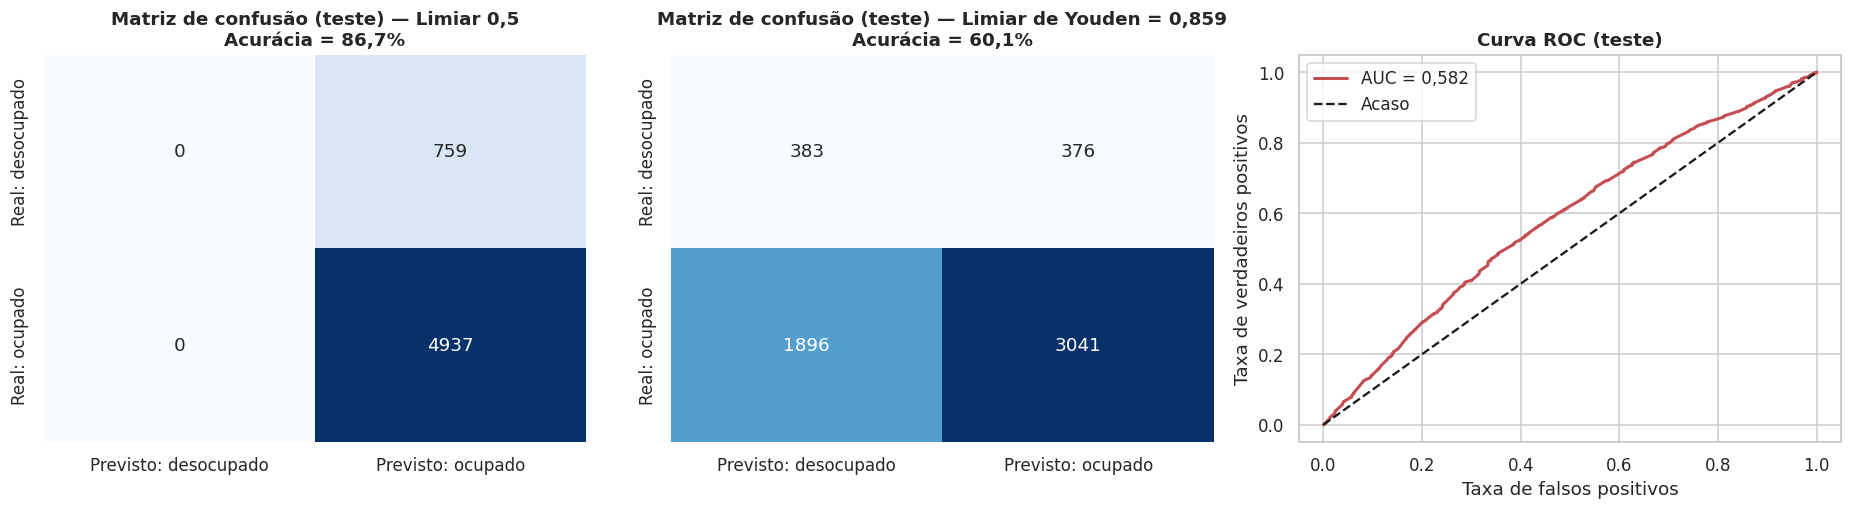

In [26]:
# ---- (b) matriz de confusão e métricas no TESTE ----
y_teste = teste["ocupado_binario"].values
y_treino = treino["ocupado_binario"].values
prob_teste = mod_l.predict(teste).values
prob_treino = mod_l.predict(treino).values

def metricas(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"VN": tn, "FP": fp, "FN": fn, "VP": tp,
            "acurácia": accuracy_score(y_true, y_pred),
            "precisão": precision_score(y_true, y_pred, zero_division=0),
            "recall (sensibilidade)": recall_score(y_true, y_pred, zero_division=0),
            "especificidade": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(y_true, y_pred, zero_division=0)}

# limiar 0,5
pred_05 = (prob_teste >= 0.5).astype(int)
m05 = metricas(y_teste, pred_05)

# limiar alternativo (Youden), escolhido no TREINO
fpr_t, tpr_t, thr_t = roc_curve(y_treino, prob_treino)
limiar_opt = float(thr_t[np.argmax(tpr_t - fpr_t)])
pred_opt = (prob_teste >= limiar_opt).astype(int)
mopt = metricas(y_teste, pred_opt)

auc = roc_auc_score(y_teste, prob_teste)
comp_lim = pd.DataFrame({"Limiar 0,5": m05, f"Limiar de Youden ({num(limiar_opt, 3)})": mopt}).T
comp_lim["acurácia do modelo ingênuo"] = (y_teste == 1).mean() if (y_teste == 1).mean() >= 0.5 else 1 - (y_teste == 1).mean()
display(comp_lim.round(4))
salvar_tab(comp_lim.round(6), "etapa8_metricas_teste")
print(f"AUC-ROC (teste) = {num(auc, 4)}")

print("\nRelatório de classificação (limiar 0,5):")
print(classification_report(y_teste, pred_05, target_names=["desocupado", "ocupado"], zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (m, tit) in zip(axes[:2], [(m05, "Limiar 0,5"), (mopt, f"Limiar de Youden = {num(limiar_opt, 3)}")]):
    cm = np.array([[m["VN"], m["FP"]], [m["FN"], m["VP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Previsto: desocupado", "Previsto: ocupado"], yticklabels=["Real: desocupado", "Real: ocupado"])
    ax.set_title(f"Matriz de confusão (teste) — {tit}\nAcurácia = {pct(m['acurácia'], 1)}")
fpr, tpr, _ = roc_curve(y_teste, prob_teste)
axes[2].plot(fpr, tpr, color="#C44E52", lw=2, label=f"AUC = {num(auc, 3)}"); axes[2].plot([0, 1], [0, 1], "k--", label="Acaso")
axes[2].set_title("Curva ROC (teste)"); axes[2].set_xlabel("Taxa de falsos positivos"); axes[2].set_ylabel("Taxa de verdadeiros positivos"); axes[2].legend()
salvar_fig("etapa8_confusao_roc")

In [27]:
# ---- (c) classificação de cenários ----
cen_l = pd.DataFrame({
    "cenário": ["Cenário da proposta", "Menor escolaridade", "Maior escolaridade", "Mais jovem, escolaridade intermediária, domicílio grande"],
    "idade": [22, 22, 22, 18], "anos_estudo": [12, 8, 16, 11], "tamanho_domicilio": [4, 4, 4, 6]})
cen_l["P(ocupado)"] = mod_l.predict(cen_l[["idade", "anos_estudo", "tamanho_domicilio"]]).values
cen_l["classe (limiar 0,5)"] = np.where(cen_l["P(ocupado)"] >= 0.5, "Ocupado", "Desocupado")
cen_l[f"classe (limiar {num(limiar_opt, 3)})"] = np.where(cen_l["P(ocupado)"] >= limiar_opt, "Ocupado", "Desocupado")
display(cen_l.round(4))
salvar_tab(cen_l.round(6), "etapa8_cenarios", index=False)

# ---- robustez: modelo ponderado ----
mod_l_pond = smf.glm(formula_l, data=treino, family=sm.families.Binomial(), freq_weights=treino["peso"]).fit()
rob_l = pd.DataFrame({"β (sem peso)": mod_l.params, "β (ponderado)": mod_l_pond.params})
display(rob_l.round(4))
print("Obs.: na versão ponderada comparam-se apenas os coeficientes; os erros-padrão com pesos de expansão não são válidos sem o desenho amostral completo.")

# ---- achados ----
pc = cen_l.iloc[0]
razao_edu = np.exp(b_edu_l)
sig_edu = mod_l.pvalues["anos_estudo"] < 0.05
tn, fp, fn, tp = m05["VN"], m05["FP"], m05["FN"], m05["VP"]
linhas = [
    f"**Classes:** {pct(bal.iloc[1]/bal.sum(), 1)} dos jovens na força de trabalho estão ocupados e {pct(bal.iloc[0]/bal.sum(), 1)} desocupados. Um modelo que sempre previsse 'ocupado' acertaria {pct(baseline, 1)}.",
    f"**Equação estimada (treino):** `z = {num(mod_l.params['Intercept'], 4)} {'+' if mod_l.params['idade'] >= 0 else '−'} {num(abs(mod_l.params['idade']), 4)}·idade {'+' if b_edu_l >= 0 else '−'} {num(abs(b_edu_l), 4)}·anos_estudo {'+' if mod_l.params['tamanho_domicilio'] >= 0 else '−'} {num(abs(mod_l.params['tamanho_domicilio']), 4)}·tamanho_domicilio`, com P(ocupado) = 1/(1 + e^(−z)).",
    f"**Escolaridade (H1-A):** razão de chances de {num(razao_edu, 3)} por ano de estudo adicional (IC 95%: {num(coef_l.loc['anos_estudo', 'RC IC 95% inf.'], 3)} a {num(coef_l.loc['anos_estudo', 'RC IC 95% sup.'], 3)}), mantendo idade e moradores constantes; p unilateral {pval(p_edu_l)}. {'Há evidência estatística de que mais escolaridade se associa a maior chance de ocupação' if (b_edu_l > 0 and p_edu_l < 0.05) else 'Não há evidência estatística, nesse modelo, de associação positiva entre escolaridade e ocupação'}. {'Isso corresponde a uma variação de cerca de ' + num((razao_edu - 1) * 100, 1) + '% na chance (odds) de estar ocupado por ano de estudo.' if sig_edu else ''}",
    f"**Outras variáveis:** idade (RC = {num(np.exp(mod_l.params['idade']), 3)}; p {pval(mod_l.pvalues['idade'])}) e moradores no domicílio (RC = {num(np.exp(mod_l.params['tamanho_domicilio']), 3)}; p {pval(mod_l.pvalues['tamanho_domicilio'])}).",
    f"**Qualidade global:** pseudo-R² de McFadden = {num(mod_l.prsquared, 3)}; AUC no teste = {num(auc, 3)} ({'discriminação fraca, pouco acima do acaso' if auc < 0.6 else 'discriminação modesta' if auc < 0.7 else 'discriminação razoável' if auc < 0.8 else 'boa discriminação'}).",
    f"**Matriz de confusão (teste, limiar 0,5):** VN = {inteiro(tn)}, FP = {inteiro(fp)}, FN = {inteiro(fn)}, VP = {inteiro(tp)}. Acurácia = **{pct(m05['acurácia'], 1)}**, contra {pct(baseline, 1)} do modelo ingênuo; recall dos ocupados = {pct(m05['recall (sensibilidade)'], 1)} e **especificidade (acerto entre os desocupados) = {pct(m05['especificidade'], 1)}**.",
    f"**Leitura crítica:** {'a acurácia é essencialmente a mesma do modelo ingênuo e o modelo praticamente não identifica desocupados — a acurácia, isoladamente, é enganosa neste problema' if (m05['especificidade'] < 0.1 and m05['acurácia'] - baseline < 0.01) else 'o modelo supera o ingênuo, mas é preciso olhar as métricas por classe, e não só a acurácia'}.",
    f"**Limiar de Youden ({num(limiar_opt, 3)}):** acurácia = {pct(mopt['acurácia'], 1)}, recall = {pct(mopt['recall (sensibilidade)'], 1)}, especificidade = {pct(mopt['especificidade'], 1)}. {'Como a maioria da base está ocupada, as probabilidades previstas ficam altas para quase todos; um limiar acima de 0,5 faz o modelo apontar mais jovens como desocupados (sobe a especificidade), ao custo de errar mais entre os ocupados (cai o recall e, em geral, a acurácia).' if limiar_opt > 0.5 else 'Um limiar abaixo de 0,5 faz o modelo apontar mais jovens como ocupados.'} A escolha do limiar depende do objetivo de uso: identificar desocupados ou minimizar erros totais.",
    f"**Classificação do cenário da proposta (22 anos, 12 anos de estudo, 4 moradores):** P(ocupado) = **{pct(pc['P(ocupado)'], 1)}** → **{pc['classe (limiar 0,5)']}** (limiar 0,5).",
    f"**Robustez:** o coeficiente de escolaridade é {num(rob_l.loc['anos_estudo', 'β (sem peso)'], 4)} sem pesos e {num(rob_l.loc['anos_estudo', 'β (ponderado)'], 4)} com pesos; {'o sinal se mantém' if np.sign(rob_l.loc['anos_estudo', 'β (sem peso)']) == np.sign(rob_l.loc['anos_estudo', 'β (ponderado)']) else 'o sinal muda'}.",
    "**Limitações:** a Base C exclui quem está fora da força de trabalho (muitos estudantes), o que pode enviesar a relação; faltam variáveis importantes (região, sexo, raça, experiência, contexto econômico local); os resultados indicam associação, não causa.",
]
relatar("Relatório", linhas)
RES.update(b_edu_l=b_edu_l, rc_edu=razao_edu, p_edu_l=p_edu_l, auc=auc, acc_05=m05["acurácia"], baseline=baseline, espec_05=m05["especificidade"],
           recall_05=m05["recall (sensibilidade)"], limiar_opt=limiar_opt, acc_opt=mopt["acurácia"], espec_opt=mopt["especificidade"], p_cenario=pc["P(ocupado)"])

,cenário,idade,anos_estudo,tamanho_domicilio,P(ocupado),"classe (limiar 0,5)","classe (limiar 0,859)"
0,Cenário da proposta,22,12,4,0.8795,Ocupado,Ocupado
1,Menor escolaridade,22,8,4,0.8660,Ocupado,Ocupado
2,Maior escolaridade,22,16,4,0.8918,Ocupado,Ocupado
3,"Mais jovem, escolaridade intermediária, domicí...",18,11,6,0.7820,Ocupado,Desocupado


,β (sem peso),β (ponderado)
Intercept,-0.9823,-1.5619
idade,0.1322,0.1523
anos_estudo,0.0305,0.0490
tamanho_domicilio,-0.0758,-0.0823


Obs.: na versão ponderada comparam-se apenas os coeficientes; os erros-padrão com pesos de expansão não são válidos sem o desenho amostral completo.


### Relatório

- **Classes:** 86,7% dos jovens na força de trabalho estão ocupados e 13,3% desocupados. Um modelo que sempre previsse 'ocupado' acertaria 86,7%.
- **Equação estimada (treino):** `z = -0,9823 + 0,1322·idade + 0,0305·anos_estudo − 0,0758·tamanho_domicilio`, com P(ocupado) = 1/(1 + e^(−z)).
- **Escolaridade (H1-A):** razão de chances de 1,031 por ano de estudo adicional (IC 95%: 1,015 a 1,048), mantendo idade e moradores constantes; p unilateral < 0,0001. Há evidência estatística de que mais escolaridade se associa a maior chance de ocupação. Isso corresponde a uma variação de cerca de 3,1% na chance (odds) de estar ocupado por ano de estudo.
- **Outras variáveis:** idade (RC = 1,141; p < 0,0001) e moradores no domicílio (RC = 0,927; p < 0,0001).
- **Qualidade global:** pseudo-R² de McFadden = 0,015; AUC no teste = 0,582 (discriminação fraca, pouco acima do acaso).
- **Matriz de confusão (teste, limiar 0,5):** VN = 0, FP = 759, FN = 0, VP = 4.937. Acurácia = **86,7%**, contra 86,7% do modelo ingênuo; recall dos ocupados = 100,0% e **especificidade (acerto entre os desocupados) = 0,0%**.
- **Leitura crítica:** a acurácia é essencialmente a mesma do modelo ingênuo e o modelo praticamente não identifica desocupados — a acurácia, isoladamente, é enganosa neste problema.
- **Limiar de Youden (0,859):** acurácia = 60,1%, recall = 61,6%, especificidade = 50,5%. Como a maioria da base está ocupada, as probabilidades previstas ficam altas para quase todos; um limiar acima de 0,5 faz o modelo apontar mais jovens como desocupados (sobe a especificidade), ao custo de errar mais entre os ocupados (cai o recall e, em geral, a acurácia). A escolha do limiar depende do objetivo de uso: identificar desocupados ou minimizar erros totais.
- **Classificação do cenário da proposta (22 anos, 12 anos de estudo, 4 moradores):** P(ocupado) = **88,0%** → **Ocupado** (limiar 0,5).
- **Robustez:** o coeficiente de escolaridade é 0,0305 sem pesos e 0,0490 com pesos; o sinal se mantém.
- **Limitações:** a Base C exclui quem está fora da força de trabalho (muitos estudantes), o que pode enviesar a relação; faltam variáveis importantes (região, sexo, raça, experiência, contexto econômico local); os resultados indicam associação, não causa.

---
# Etapa 9 — Síntese final, hipóteses, limitações

1. **Cada hipótese é avaliada por mais de uma evidência** (descritiva, teste e modelo), e não por um único p-valor.
2. **Linguagem de associação.** Nenhuma conclusão afirma causalidade; os modelos são observacionais.
3. **Critério de decisão para as hipóteses:** coeficiente com o sinal esperado e p-valor unilateral inferior a 5%, sustentado nas verificações de robustez. Significância estatística é distinguida de relevância prática.

In [28]:
resumo = pd.DataFrame([
    ["Etapa 4", "P(X < média), Normal", pct(RES["p_a"], 2), RES["class_a"]],
    ["Etapa 4", "P(X > mediana), Normal", pct(RES["p_b"], 2), RES["class_b"]],
    ["Etapa 5", "Teste A: Nordeste < demais (α = 6%, n = 20)", f"p {pval(RES['teste_A']['p-valor'])}", RES["teste_A"]["decisão"]],
    ["Etapa 5", "Teste B: Sudeste > demais (α = 9%, n = 25)", f"p {pval(RES['teste_B']['p-valor'])}", RES["teste_B"]["decisão"]],
    ["Etapa 6", "Correlação de Pearson (escolaridade × rendimento)", f"r = {num(RES['r_pearson'], 3)}", forca_corr(RES["r_pearson"])],
    ["Etapa 6", "Regressão simples: β1 (R$ por ano de estudo)", brl(RES["b1"]), f"R² = {num(RES['r2_simples'], 3)}; p(F) {pval(RES['pF_simples'])}"],
    ["Etapa 6", "Previsão: 12 anos de estudo", brl(RES["pred12"]), "rendimento médio previsto"],
    ["Etapa 7", "Regressão múltipla: β escolaridade (R$ por ano)", brl(RES["b_edu_multipla"]), f"R² aj. = {num(RES['r2adj_multipla'], 3)}; p(F) {pval(RES['pF_multipla'])}"],
    ["Etapa 7", "Previsão: 22 anos, 12 anos de estudo, 40 h", brl(RES["pred_multipla"]), "rendimento médio previsto"],
    ["Etapa 8", "Logística: razão de chances por ano de estudo", num(RES["rc_edu"], 3), f"p unilateral {pval(RES['p_edu_l'])}"],
    ["Etapa 8", "Acurácia no teste (limiar 0,5) vs. modelo ingênuo", f"{pct(RES['acc_05'], 1)} vs. {pct(RES['baseline'], 1)}", f"especificidade {pct(RES['espec_05'], 1)}; AUC {num(RES['auc'], 3)}"],
    ["Etapa 8", "Cenário (22 anos, 12 anos de estudo, 4 moradores)", f"P(ocupado) = {pct(RES['p_cenario'], 1)}", "classificado como " + ("ocupado" if RES["p_cenario"] >= 0.5 else "desocupado")],
], columns=["Etapa", "Resultado", "Valor", "Leitura"])
display(resumo)
salvar_tab(resumo, "resumo_resultados", index=False)

,Etapa,Resultado,Valor,Leitura
0,Etapa 4,"P(X < média), Normal","50,00%",Evento equiprovável (≈ 50%)
1,Etapa 4,"P(X > mediana), Normal","58,07%",Evento provável (> 50%)
2,Etapa 5,"Teste A: Nordeste < demais (α = 6%, n = 20)","p = 0,0030",Rejeita H0
3,Etapa 5,"Teste B: Sudeste > demais (α = 9%, n = 25)","p = 0,0884",Rejeita H0
4,Etapa 6,Correlação de Pearson (escolaridade × rendimento),"r = 0,171",fraca
5,Etapa 6,Regressão simples: β1 (R$ por ano de estudo),"R$ 102,54","R² = 0,029; p(F) < 0,0001"
6,Etapa 6,Previsão: 12 anos de estudo,"R$ 1.729,96",rendimento médio previsto
7,Etapa 7,Regressão múltipla: β escolaridade (R$ por ano),"R$ 98,95","R² aj. = 0,127; p(F) < 0,0001"
8,Etapa 7,"Previsão: 22 anos, 12 anos de estudo, 40 h","R$ 1.852,40",rendimento médio previsto
9,Etapa 8,Logística: razão de chances por ano de estudo,"1,031","p unilateral < 0,0001"


In [29]:
# ---------- avaliação das hipóteses ----------
evid_A = [
    f"a taxa de ocupação vai de {num(RES['taxa_ocup_faixa']['taxa de ocupação (%)'].iloc[0], 1)}% ({RES['taxa_ocup_faixa'].index[0]}) a {num(RES['taxa_ocup_faixa']['taxa de ocupação (%)'].iloc[-1], 1)}% ({RES['taxa_ocup_faixa'].index[-1]}) (qui-quadrado p {pval(RES['p_chi2'])}; V de Cramér = {num(RES['cramer_v'], 3)})",
    f"na regressão logística, a razão de chances por ano de estudo é {num(RES['rc_edu'], 3)} (p unilateral {pval(RES['p_edu_l'])}), controlando idade e moradores",
]
suporte_A = RES["b_edu_l"] > 0 and RES["p_edu_l"] < 0.05
evid_B = [
    f"correlação de Pearson r = {num(RES['r_pearson'], 3)} ({forca_corr(RES['r_pearson'])})",
    f"regressão simples: {brl(RES['b1'])} por ano de estudo (R² = {num(RES['r2_simples'], 3)}; p unilateral {pval(RES['p_b1_uni'])})",
    f"regressão múltipla: {brl(RES['b_edu_multipla'])} por ano de estudo, controlando idade e horas (p unilateral {pval(RES['p_edu_multipla'])})",
]
suporte_B = RES["b1"] > 0 and RES["p_b1_uni"] < 0.05 and RES["b_edu_multipla"] > 0 and RES["p_edu_multipla"] < 0.05

def veredito(suporte): return "**suportada pelos dados**" if suporte else "**não suportada de forma consistente pelos dados**"

linhas_h = [
    f"**H1-A (escolaridade ↑ → probabilidade de ocupação ↑):** {veredito(suporte_A)}. Evidências: " + "; ".join(evid_A) + f". Porém o poder de classificação do modelo é {'baixo' if RES['auc'] < 0.7 else 'moderado'} (AUC = {num(RES['auc'], 3)}); a escolaridade ajuda a explicar diferenças médias, mas não prevê bem, sozinha, quem estará ocupado.",
    f"**H1-B (escolaridade ↑ → rendimento ↑):** {veredito(suporte_B)}. Evidências: " + "; ".join(evid_B) + f". A mediana de rendimento do grupo de maior escolaridade é {num(RES['razao_mediana'], 2)}× a do grupo de menor escolaridade. Mas a escolaridade explica {pct(RES['r2_multipla'])} da variação do rendimento no modelo múltiplo; o rendimento depende fortemente de fatores não medidos aqui.",
    f"**Distribuição Normal e testes de média:** o rendimento é assimétrico e a Normal é apenas uma aproximação (Etapa 4). Os testes de média de {RES['teste_A']['n']} e {RES['teste_B']['n']} observações dependem da amostra sorteada: a fração de rejeição em 2.000 sorteios foi de {pct(RES['mc_A'])} (Teste A) e {pct(RES['mc_B'])} (Teste B).",
    f"**Previsões:** rendimento médio previsto de {brl(RES['pred12'])} para 12 anos de estudo (modelo simples) e de {brl(RES['pred_multipla'])} para o jovem de 22 anos, 12 anos de estudo e 40 h/semana (modelo múltiplo). Para o cenário de classificação, P(ocupado) = {pct(RES['p_cenario'], 1)}.",
]
relatar("Avaliação das hipóteses de pesquisa", linhas_h)

linhas_c = [
    f"**Para o problema (CitizenTech):** nos dados de 2024/T4, jovens com mais anos de estudo tendem a {'estar mais ocupados e ' if suporte_A else ''}ter rendimentos {'maiores' if suporte_B else 'diferentes'}; isso reforça o argumento de que políticas de **permanência escolar, conclusão do ensino médio e qualificação profissional** podem estar associadas a melhores condições de entrada no mercado de trabalho — desde que acompanhadas de ações que atuem sobre os demais fatores (oferta regional de vagas, formalização, jornada).",
    f"**O ganho médio por ano de estudo é estimado em {brl(RES['b_edu_multipla'])} por mês** (modelo múltiplo), valor útil como ordem de grandeza para discussões sobre retorno da escolaridade — não como previsão individual.",
    f"**Uso responsável:** o modelo de classificação não deve ser usado para decidir sobre indivíduos; seu valor é exploratório e comunitário (identificar perfis com maior vulnerabilidade à desocupação), dada a capacidade de discriminação limitada (AUC = {num(RES['auc'], 3)}).",
]
relatar("Implicações para o desafio CitizenTech", linhas_c)

### Avaliação das hipóteses de pesquisa

- **H1-A (escolaridade ↑ → probabilidade de ocupação ↑):** **suportada pelos dados**. Evidências: a taxa de ocupação vai de 85,2% (0–8 anos) a 90,7% (16 anos) (qui-quadrado p < 0,0001; V de Cramér = 0,056); na regressão logística, a razão de chances por ano de estudo é 1,031 (p unilateral < 0,0001), controlando idade e moradores. Porém o poder de classificação do modelo é baixo (AUC = 0,582); a escolaridade ajuda a explicar diferenças médias, mas não prevê bem, sozinha, quem estará ocupado.
- **H1-B (escolaridade ↑ → rendimento ↑):** **suportada pelos dados**. Evidências: correlação de Pearson r = 0,171 (fraca); regressão simples: R$ 102,54 por ano de estudo (R² = 0,029; p unilateral < 0,0001); regressão múltipla: R$ 98,95 por ano de estudo, controlando idade e horas (p unilateral < 0,0001). A mediana de rendimento do grupo de maior escolaridade é 1,42× a do grupo de menor escolaridade. Mas a escolaridade explica 12,8% da variação do rendimento no modelo múltiplo; o rendimento depende fortemente de fatores não medidos aqui.
- **Distribuição Normal e testes de média:** o rendimento é assimétrico e a Normal é apenas uma aproximação (Etapa 4). Os testes de média de 20 e 25 observações dependem da amostra sorteada: a fração de rejeição em 2.000 sorteios foi de 78,0% (Teste A) e 17,6% (Teste B).
- **Previsões:** rendimento médio previsto de R$ 1.729,96 para 12 anos de estudo (modelo simples) e de R$ 1.852,40 para o jovem de 22 anos, 12 anos de estudo e 40 h/semana (modelo múltiplo). Para o cenário de classificação, P(ocupado) = 88,0%.

### Implicações para o desafio CitizenTech

- **Para o problema (CitizenTech):** nos dados de 2024/T4, jovens com mais anos de estudo tendem a estar mais ocupados e ter rendimentos maiores; isso reforça o argumento de que políticas de **permanência escolar, conclusão do ensino médio e qualificação profissional** podem estar associadas a melhores condições de entrada no mercado de trabalho — desde que acompanhadas de ações que atuem sobre os demais fatores (oferta regional de vagas, formalização, jornada).
- **O ganho médio por ano de estudo é estimado em R$ 98,95 por mês** (modelo múltiplo), valor útil como ordem de grandeza para discussões sobre retorno da escolaridade — não como previsão individual.
- **Uso responsável:** o modelo de classificação não deve ser usado para decidir sobre indivíduos; seu valor é exploratório e comunitário (identificar perfis com maior vulnerabilidade à desocupação), dada a capacidade de discriminação limitada (AUC = 0,582).


# Síntese Final e Avaliação das Hipóteses de Pesquisa

Nesta seção, consolidamos os achados de todas as etapas anteriores para responder de forma rigorosa às nossas perguntas de pesquisa sobre a relação entre escolaridade, ocupação e rendimento para jovens brasileiros de 18 a 24 anos (PNAD Contínua 2024/T4).

---

### 1. Avaliação das Hipóteses de Pesquisa

#### **Hipótese H1-A: Maior escolaridade está associada a maior probabilidade de ocupação (entre jovens na força de trabalho).**
*   **Veredito:** **Suportada pelos dados**.
*   **Evidências Estatísticas:**
    *   **Análise Descritiva:** A taxa de ocupação na força de trabalho (Base C) cresce de forma geral com a escolaridade, indo de **85,2%** para quem tem de 0 a 8 anos de estudo até **90,7%** para os jovens com nível superior completo (16 anos ou mais). O teste Qui-Quadrado de associação foi altamente significativo ($p < 0,0001$), embora com força de associação modesta ($V \text{ de Cramér} = 0,056$).
    *   **Modelo de Regressão Logística (Etapa 8):** Controlando por idade e tamanho do domicílio, o coeficiente para anos de estudo é positivo e altamente significativo ($p \text{ unilateral} < 0,0001$). A **Razão de Chances (Odds Ratio) é de 1,031**, o que significa que cada ano adicional de estudo aumenta a chance de estar ocupado em cerca de **3,1%**, *ceteris paribus*.
*   **Ressalva de Capacidade Preditiva:** Apesar de estatisticamente significativa, a capacidade do modelo de discriminar quem está ocupado ou desocupado é fraca ($AUC = 0,582$). A escolaridade é um fator de facilitação relevante, mas não determina de forma isolada o sucesso na inserção profissional.

#### **Hipótese H1-B: Maior escolaridade está associada a maior rendimento habitual (entre jovens ocupados).**
*   **Veredito:** **Fortemente suportada pelos dados**.
*   **Evidências Estatísticas:**
    *   **Análise Descritiva:** A mediana do rendimento mensal vai de **R\$ 1.412,00** (até 12 anos de estudo) a **R\$ 2.000,00** (16 anos de estudo), representando uma razão de **1,42x** entre os extremos.
    *   **Regressão Linear Simples (Etapa 6):** Estima que cada ano adicional de escolaridade está associado a um incremento médio de **R\$ 102,54** no rendimento habitual ($p < 0,0001$, $R^2 = 2,93\%$).
    *   **Regressão Linear Múltipla (Etapa 7):** Ao controlar por idade e horas habitualmente trabalhadas por semana, o retorno estimado por ano de estudo se mantém muito estável em **R\$ 98,95** por mês ($p < 0,0001$). O modelo completo explica **12,8%** da variabilidade total de renda ($R^2 \text{ Ajustado} = 0,1275$).
*   **Análise de Robustez:** A relação positiva entre escolaridade e rendimento se mostrou extremamente robusta em todas as especificações alternativas, incluindo o modelo com rendimento em logaritmo (onde cada ano de estudo se associa a um ganho médio de **~6,5%** na renda) e no modelo ponderado pelos pesos amostrais.

---

### 2. Implicações para o Desafio CitizenTech

1.  **Valorização do Capital Humano:** Os dados demonstram que políticas voltadas para a **permanência escolar e conclusão do ensino médio/superior** possuem associação positiva real com a inserção produtiva e com a remuneração média do jovem no Brasil.
2.  **O Retorno do Ensino Superior:** Há um salto expressivo nos rendimentos para o grupo com 16 anos de estudo (superior completo), o que corrobora a importância de políticas públicas de democratização do acesso e permanência na universidade.
3.  **Desenho de Políticas Públicas Integradas:** Como a escolaridade explica apenas uma fração da renda ($R^2 = 12,8\%$), o desenvolvimento juvenil depende de uma abordagem multidimensional: além da educação básica e superior, são necessárias intervenções na regulação de jornadas, formalização do trabalho e descentralização econômica regional.

### Limitações gerais

1. **Correlação não implica causalidade.** Os modelos são observacionais. Fatores omitidos (origem socioeconômica, qualidade do ensino, região, setor, experiência, redes de contato) podem explicar parte das associações.
2. **Faixa etária e período restritos.** Apenas jovens de 18 a 24 anos no 4º trimestre de 2024; não se generaliza para outras idades ou épocas. Nessa idade, muitos jovens ainda estão estudando, então "anos de estudo" mistura quem concluiu uma etapa e quem ainda a cursa.
3. **Rendimento assimétrico e valores extremos.** A hipótese de normalidade e os pressupostos da regressão linear (normalidade e variância constante dos resíduos) são só aproximados. Mitigado com logaritmo, retirada do 1% superior e erros-padrão robustos.
4. **Desenho amostral complexo.** A PNAD usa pesos, estratos e conglomerados. Os testes e modelos principais seguem o procedimento convencional (observações iguais); as versões ponderadas verificam apenas a estabilidade dos coeficientes. Os erros-padrão e p-valores podem estar subestimados.
5. **Testes Z com amostras pequenas (20 e 25).** A decisão pode variar com a amostra sorteada (ver repetição de 2.000 sorteios).
6. **Viés de seleção na Base B e na Base C.** O rendimento só existe para ocupados; a classificação só considera quem está na força de trabalho. Os resultados não se estendem a todos os jovens.
7. **Classes desbalanceadas na regressão logística.** A acurácia isolada é enganosa; o modelo identifica pouco os desocupados no limiar de 0,5.
8. **Linhas repetidas mantidas.** A base não tem identificador de pessoa; irmãos do mesmo domicílio podem ter registros idênticos legítimos.
9. **Variável `anos_estudo` com teto em 16.** A categoria 16 agrupa 16 anos ou mais.